<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/DPVQC_PrivateClassification_Watkins2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Differentially private hybrid VQC (DP-SGD on a variational quantum classifier): Watkins, Chen and Yoo (2023) step by step

This notebook re-implements, runs and checks the method of

> William M. Watkins, Samuel Yen-Chi Chen and Shinjae Yoo,
> "Quantum machine learning with differential privacy", *Scientific Reports* 13, 2453 (2023).
> https://doi.org/10.1038/s41598-022-24082-z

The paper publishes no code ("data available on reasonable request"), so everything below is written from the method as the
paper describes it. The paper used PennyLane + Qulacs + PyTorch + PyVacy; here the circuits are drawn and verified with
PennyLane, but trained with a small exact NumPy simulator (asserted equal to the PennyLane circuits), and DP-SGD and the privacy
accountant are implemented from scratch.

**What the notebook does.**
1. Loads real MNIST images of the digits 0 and 1 (Hugging Face mirror, cached) and generates the paper's three scikit-learn
   2-D benchmarks ("blobs", "moons", "circles").
2. Builds the paper's hybrid quantum-classical classifier: two variational circuit blocks (Rot layers + CNOTs, expectation values
   of sigma_z), the first block fed by amplitude encoding (MNIST) or by angle encoding RY(arctan x), RZ(arctan x^2) (2-D data), the second
   block fed with the outputs of the first (288 trainable parameters for MNIST, 24 for the 2-D tasks).
3. Trains it with **DP-SGD**: per-sample gradients, clipping to L2 norm S = 1, Gaussian noise of standard deviation sigma * S,
   RMSprop updates, and a Renyi-DP **privacy accountant** that turns the noise multiplier into the (epsilon, delta = 1e-5) the paper prints.
4. Trains the paper's classical control (a tiny tanh network) with and without DP on exactly the same inputs, plus standard
   scikit-learn baselines without DP.
5. Re-draws the paper's Table 2, Table 3 / Table 4 and Figs. 8, 10 and 13 and gives every checkable claim an explicit verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a pinned
PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no IBM account and no gated dataset is needed
(MNIST is public; the optional Hugging Face token is read only from the environment or Colab Secrets and is never printed).

**Runtime.** ﻿With `FAST_MODE = True` (600 train / 400 test images, 10 epochs, three noise levels, one seed) the notebook runs in about 7 minutes
on a CPU. With `FAST_MODE = False` (the paper's 30 epochs, 1500 / 1000 images, all ten noise levels, 3 seeds per VQC cell, 5 seeds for the
2-D tasks) the executed copy committed here took 127 minutes of wall-clock time on a heavily shared CPU; the 10-qubit VQC runs dominate
(about 3 minutes per 150-step run) and the process used about 25 minutes of CPU time, so an idle machine needs well under an hour. Every number shown below comes from that single full run.

**What you get at the end.** The accuracy of the private and non-private quantum and classical models for every noise level, the
privacy budget epsilon actually spent, and a table that says, claim by claim, which of the paper's numbers this re-implementation
reproduces and which it does not.

## The paper in one page

**Problem.** Machine-learning models leak information about their training data (membership inference, data extraction, model
inversion). The paper asks whether a *quantum* classifier can be trained with *differential privacy* (DP) and whether it then keeps
more accuracy than a comparable classical network.

**Decision.** Binary classification: a point of one of three 2-D benchmark sets, or a handwritten digit that is a "0" or a "1".

**Method.** A hybrid quantum-classical model: a variational quantum circuit (VQC) simulated on a classical computer, whose
gradients are computed on the classical side and then privatised with DP-SGD (Abadi et al., 2016): the gradient of every training
example is clipped to L2 norm S, Gaussian noise N(0, sigma^2 S^2) is added to the summed gradients, and the update is made with
RMSprop (lr 0.05, alpha 0.9, momentum 0.5). The privacy loss epsilon follows from sigma, delta = 1e-5, the sampling rate and the
number of iterations through a moments accountant (PyVacy).

**Data.** (i) scikit-learn "blobs" and "moons" (200 points each) and "circles" (1000 points), 60 % / 40 % train / test;
(ii) MNIST digits 0 and 1, 60 % / 40 %. **Preprocessing:** none; the 2-D inputs enter through arctan, the 784 MNIST pixels are
zero-padded to 1024 and amplitude-encoded on 10 qubits.

**Architecture.** 2-D: two blocks of 2 qubits and 2 layers (2 x 12 = 24 parameters) against a 2-7-2 tanh network (36 parameters).
MNIST: block 1 = 10 qubits, 8 layers, 4 read-outs (240 parameters), block 2 = 4 qubits, 4 layers, 2 read-outs (48 parameters),
288 in total, against a 1024-1-2 tanh network (1029 parameters). Loss: cross-entropy. 30 epochs.

**Claims checked here.**

| Where | Claim |
|---|---|
| Table 2 | Accuracies of NN and VQC on blobs / moons / circles without DP and at eps = 1.628 and 0.681 (e.g. circles: VQC 0.998 / 1.00 vs NN 0.88 / 0.86 under DP) |
| Table 3, Fig. 13 | MNIST 0 vs 1 accuracy of NN and VQC for ten noise levels, eps from 1.73 down to 0.07 (e.g. VQC 0.977 at eps 1.73, NN 0.984; VQC 0.965 vs NN 0.929 at eps 0.406) |
| Abstract, Discussion | The DP-VQC exceeds 90 % accuracy for eps between 0.5 and 1.0; it beats the DP-NN for eps between 0.41 and 1.34; below eps 0.25 the NN is better |
| Experiments | 288 VQC parameters = 28 % of the NN's 1029; 24 vs 36 for the 2-D tasks |
| Appendix | The printed eps values follow from the noise multiplier through the accountant |

## What follows the paper and what had to be chosen

Where the paper is silent this notebook makes a choice, marked `# CHOICE:` in the code. The most consequential ones:

| Item | Paper | This notebook |
|---|---|---|
| Software | PennyLane + Qulacs + PyTorch + PyVacy | Exact NumPy state-vector simulator with adjoint differentiation (per-sample gradients), **asserted equal to the PennyLane QNodes** (outputs and gradients, 1e-10); DP-SGD, RMSprop and the accountant written here |
| Circuit blocks | Figs. 1, 6, 7, 11, 12: RY(arctan x), RZ(arctan x^2) or amplitude encoding, Rot layers, CNOTs, read-out sigma_z | Same; **CHOICE:** the CNOT pattern of one layer is not in the text, a ring CNOT(i, i+1 mod n) is used; **CHOICE:** read-out on the first 4 (block 1) / 2 (block 2) qubits |
| Output to loss | "cross-entropy"; outputs interpreted as class probabilities | **CHOICE:** the two <Z> values are the logits of a softmax cross-entropy |
| Initialisation | N(0,1) scaled by 0.01 | Same (VQC); Xavier-uniform weights and zero biases for the classical net |
| Optimiser | RMSprop, lr 0.05, alpha 0.9, eps 1e-8, momentum 0.5 | Same, with torch.optim.RMSprop update rules (unit-tested) |
| DP-SGD | Clip S = 1, noise sigma * S, delta = 1e-5, batch 32, "# of Iter. 5" | Per-sample clipping, Gaussian noise on the sum, division by 32; **CHOICE:** Poisson sampling (each sample enters a batch with probability 32/N, as PyVacy's i.i.d. sampler); **CHOICE:** "5 iterations" is read as 5 DP-SGD iterations per epoch, i.e. 30 epochs = 150 noisy steps (non-private runs make full passes) |
| Accounting | PyVacy (appendix not in the PDF text) | Renyi-DP accountant for the sampled Gaussian mechanism (integer orders) with the 2019 conversion; reproduces the paper's eps = 1.628 and 0.681 exactly (N = 120, 5 iterations, sigma = 2.5 and 5.0) |
| Noise multipliers, MNIST | "iterating the noise multiplier from 1.0 to 5.0", values not listed | **CHOICE:** the ten sigma are recovered by inverting the paper's ten eps values with the accountant (N = 1500, 5 iterations; this setting gives eps(sigma = 1) = 1.7321 against the paper's 1.7307) |
| 2-D data | scikit-learn blobs, moons (200), circles (1000); noise levels not given | **CHOICE:** make_blobs(centers=2, cluster_std=1.0), make_moons(noise=0.1), make_circles(noise=0.05, factor=0.5), random_state = 42 |
| MNIST subset | digits 0 and 1, 60/40, size not given | **CHOICE:** 2500 random images (natural 0/1 mix) of the 12,665 in the training split: 1500 train / 1000 test, the N = 1500 implied by the accountant |
| Classical NN | 2-7-2 with 36 parameters; 1024-1-2 with 1029; tanh after each layer, softmax at the end | Same architecture (tanh also on the output layer, as the text says); a 2-7-2 net with biases has 37 parameters, not 36 |
| Seeds | not stated (single runs apparently) | SEED = 42; mean +- std over several seeds (numbers in the configuration cell) |
| Hardware | none: noise-free simulation | none |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_v] = "1"          # one BLAS thread: reproducible timings and polite on shared machines (must be set before numpy is imported)
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub pillow pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False       # True: class demo in about 8 minutes. False: the paper-size run (see the runtime note at the top).
SEED      = 42                 # CHOICE: the paper gives no seed
DATA_DIR  = "data"             # cache for the MNIST download (relative to the working directory)

# --- DP-SGD hyper-parameters, Table 1 of the paper ---
BATCH, CLIP, LR, DELTA = 32, 1.0, 0.05, 1e-5   # batch size, L2 clip S, RMSprop learning rate, delta
ITERS_PER_EPOCH = 5            # Table 1 "# of Iter. = 5". CHOICE: read as DP-SGD iterations (mini-batches) per epoch, see the accountant section
# RMSprop alpha = 0.9, eps = 1e-8, momentum = 0.5 are set inside the optimiser class below.

if FAST_MODE:
    MNIST_N_TOTAL   = 1000                 # 600 train / 400 test
    EPOCHS          = 10
    SIGMA_IDX       = [0, 4, 9]            # three of the ten noise levels of Table 3 (eps = 1.73, 0.41, 0.07)
    SEEDS_MNIST_NN  = [42]
    SEEDS_MNIST_VQC = [42]
    SEEDS_2D        = [42, 43]
    EXT_SIGMAS      = [0.0, 0.3]
else:
    MNIST_N_TOTAL   = 2500                 # CHOICE: 1500 train / 1000 test (60/40); the paper's accountant implies N_train = 1500
    EPOCHS          = 30                   # paper: 30 epochs
    SIGMA_IDX       = list(range(10))      # all ten rows of Table 3
    SEEDS_MNIST_NN  = [42, 43, 44]
    SEEDS_MNIST_VQC = [42, 43, 44]
    SEEDS_2D        = [42, 43, 44, 45, 46]
    EXT_SIGMAS      = [0.0, 0.1, 0.3, 0.5, 0.7]

In [3]:
import io, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning); warnings.filterwarnings("ignore", category=FutureWarning)

# Hugging Face token: only needed for gated datasets. MNIST is public, so this stays None unless you have set a token.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
CLASS_COLORS = ["#0072B2", "#D55E00"]             # colour-blind-safe pair used for every class plot
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
import pennylane as qml, scipy, sklearn
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| epochs =", EPOCHS, "| MNIST subset =", MNIST_N_TOTAL, "| noise levels run =", len(SIGMA_IDX))

numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | pennylane 0.45.1
FAST_MODE = False | epochs = 30 | MNIST subset = 2500 | noise levels run = 10


## 1. Data: MNIST digits 0 and 1 and the three 2-D benchmarks

**MNIST.** The 60,000 training images are fetched from the Hugging Face mirror `ylecun/mnist` (a 15 MB parquet file; public, no
token needed; the Keras mirror is the fallback), the images of the digits 0 and 1 are kept (12,665 images) and cached as a small `.npz`.
The paper does not say how many it used. Its privacy accountant (see Section 4) reproduces its printed epsilon for N = 1500
training samples and 60 % / 40 % is the paper's split, so **2500 random images** are drawn (1500 train, 1000 test), pixels divided by 255
and zero-padded from 784 to 1024 numbers.

**2-D sets.** Generated with scikit-learn exactly as the paper says (200 points for blobs and moons, 1000 for circles, 60 % / 40 %);
the paper does not give the generator noise, so the values in the code are choices. These are generated observations by
construction, not a substitute for some other dataset: the paper itself generates them this way.

Every split is stratified with `random_state = SEED`; every transform that is fitted (here only PCA, for the figures) is fitted on the
training split.

In [4]:
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.model_selection import train_test_split

def load_mnist01(data_dir):
    """All MNIST *training* images of the digits 0 and 1 (12,665 images): uint8 array (n, 784) and labels. Cached as .npz."""
    cache = os.path.join(data_dir, "mnist_digits01_train.npz")
    if os.path.exists(cache):
        d = np.load(cache); return d["X"], d["y"], "cache"
    try:                                                   # 1st choice: Hugging Face mirror ylecun/mnist (public; token optional)
        from huggingface_hub import hf_hub_download
        from PIL import Image
        p = hf_hub_download("ylecun/mnist", "mnist/train-00000-of-00001.parquet", repo_type="dataset",
                            local_dir=data_dir, token=HF_TOKEN)
        df = pd.read_parquet(p)
        y = df["label"].to_numpy(); keep = np.flatnonzero(y <= 1)
        X = np.stack([np.array(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"]))).reshape(-1) for i in keep]).astype(np.uint8)
        y = y[keep].astype(int); src = "huggingface ylecun/mnist"
    except Exception as e:                                 # 2nd choice: the Keras mirror of the original IDX files
        import requests
        print("Hugging Face route failed (%s); using the Keras mirror" % type(e).__name__)
        r = requests.get("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", timeout=120); r.raise_for_status()
        d = np.load(io.BytesIO(r.content)); keep = np.flatnonzero(d["y_train"] <= 1)
        X = d["x_train"][keep].reshape(len(keep), -1).astype(np.uint8); y = d["y_train"][keep].astype(int); src = "keras mnist.npz"
    np.savez_compressed(cache, X=X, y=y)
    return X, y, src

def make_mnist_task(X_u8, y, n_total, seed, test_size=0.4):
    """CHOICE: random subset of n_total images (natural 0/1 mix), pixels/255, zero-padded 784 -> 1024, stratified 60/40 split."""
    sel = np.random.default_rng(seed).choice(len(y), n_total, replace=False)
    X = np.zeros((n_total, 1024)); X[:, :784] = X_u8[sel] / 255.0
    return train_test_split(X, y[sel], test_size=test_size, stratify=y[sel], random_state=seed)

def make_2d_task(name, seed, test_size=0.4):
    """The paper's three scikit-learn mini-benchmarks. CHOICE: generator noise levels (the paper does not give them)."""
    if name == "blobs":
        X, y = make_blobs(n_samples=200, centers=2, n_features=2, cluster_std=1.0, random_state=seed)
    elif name == "moons":
        X, y = make_moons(n_samples=200, noise=0.1, random_state=seed)
    else:
        X, y = make_circles(n_samples=1000, noise=0.05, factor=0.5, random_state=seed)
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)

In [5]:
X_pool, y_pool, MNIST_SRC = load_mnist01(DATA_DIR)
mn_Xtr, mn_Xte, mn_ytr, mn_yte = make_mnist_task(X_pool, y_pool, MNIST_N_TOTAL, SEED)
TASKS2D = {name: make_2d_task(name, SEED) for name in ["blobs", "moons", "circles"]}     # name -> (Xtr, Xte, ytr, yte)
print("MNIST 0/1 pool:", X_pool.shape, "from", MNIST_SRC, "| task: train", mn_Xtr.shape, "test", mn_Xte.shape)
for name, (a, b, c, d) in TASKS2D.items():
    print("%-8s train %s test %s" % (name, a.shape, b.shape))

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

MNIST 0/1 pool: (12665, 784) from huggingface ylecun/mnist | task: train (1500, 1024) test (1000, 1024)
blobs    train (120, 2) test (80, 2)
moons    train (120, 2) test (80, 2)
circles  train (600, 2) test (400, 2)


## Dataset Exploration and Visualisation

For each dataset this section prints the shape, the feature names and the original label values with their counts, plots the real class
distribution, and draws 2-D scatter plots in which every point is a real (or, for the sklearn sets, generated) observation coloured by its
ground-truth label. Filled markers are training points, open markers are test points.

=== Dataset 1: MNIST handwritten digits '0' and '1' (real images) ===
source                : huggingface ylecun/mnist
pool shape            : (12665, 784) (images x 784 grey values, uint8 0..255)
feature names         : pixel_0 ... pixel_783 (28x28 image, row-major); the model sees them divided by 255 and zero-padded to 1024
original label values : {0: 5923, 1: 6742} (the other eight digits are not used by the paper)
task subset           : 2500 images drawn at random from the pool -> train (1500, 1024), test (1000, 1024)
train class counts    : {0: 682, 1: 818} | test class counts: {0: 454, 1: 546}


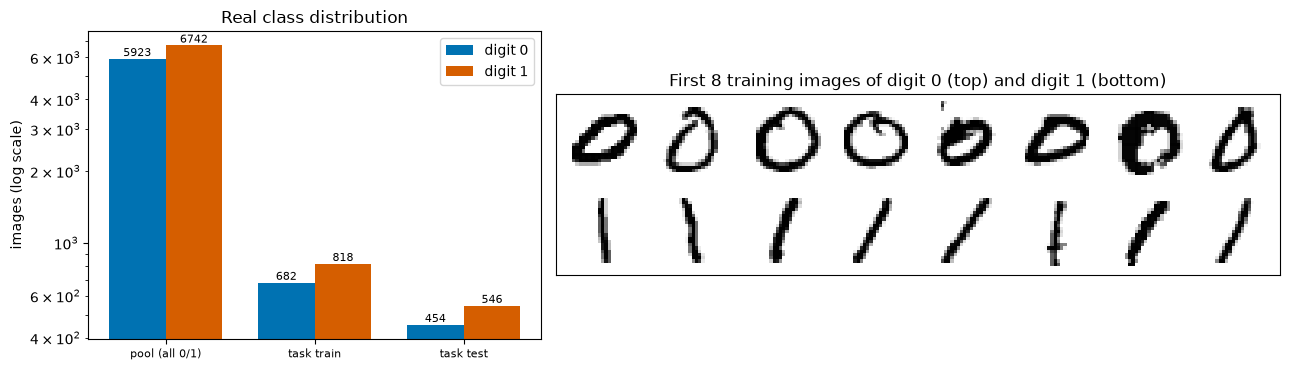

In [6]:
print("=== Dataset 1: MNIST handwritten digits '0' and '1' (real images) ===")
print("source                :", MNIST_SRC)
print("pool shape            :", X_pool.shape, "(images x 784 grey values, uint8 0..255)")
print("feature names         : pixel_0 ... pixel_783 (28x28 image, row-major); the model sees them divided by 255 and zero-padded to 1024")
print("original label values :", {int(k): int(v) for k, v in zip(*np.unique(y_pool, return_counts=True))},
      "(the other eight digits are not used by the paper)")
print("task subset           : %d images drawn at random from the pool -> train %s, test %s" % (len(mn_ytr) + len(mn_yte), mn_Xtr.shape, mn_Xte.shape))
print("train class counts    :", {int(k): int(v) for k, v in zip(*np.unique(mn_ytr, return_counts=True))},
      "| test class counts:", {int(k): int(v) for k, v in zip(*np.unique(mn_yte, return_counts=True))})

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
splits = {"pool (all 0/1)": y_pool, "task train": mn_ytr, "task test": mn_yte}
xpos = np.arange(len(splits)); wd = 0.38
for d in (0, 1):
    axs[0].bar(xpos + (d - 0.5) * wd, [int((v == d).sum()) for v in splits.values()], wd, color=CLASS_COLORS[d], label="digit %d" % d)
for i, v in enumerate(splits.values()):
    for d in (0, 1):
        axs[0].text(i + (d - 0.5) * wd, (v == d).sum(), str(int((v == d).sum())), ha="center", va="bottom", fontsize=8)
axs[0].set_xticks(xpos); axs[0].set_xticklabels(splits.keys(), fontsize=8); axs[0].set_yscale("log")
axs[0].set_ylabel("images (log scale)"); axs[0].set_title("Real class distribution"); axs[0].legend()
rows = []
for d in (0, 1):
    idx = np.flatnonzero(mn_ytr == d)[:8]
    rows.append(np.hstack([mn_Xtr[i, :784].reshape(28, 28) for i in idx]))
axs[1].imshow(np.vstack(rows), cmap="gray_r"); axs[1].set_xticks([]); axs[1].set_yticks([])
axs[1].set_title("First 8 training images of digit 0 (top) and digit 1 (bottom)")
plt.tight_layout(); plt.show()

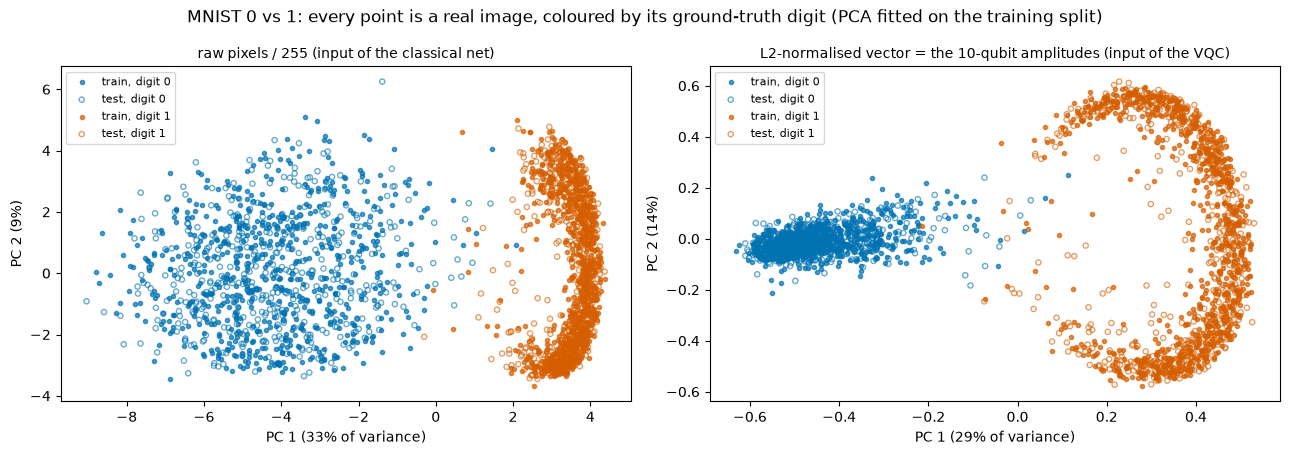

The VQC encodes the normalised pixel vector directly as amplitudes (no angle scaling is used by block 1); block 2 uses angle encoding of block 1's four outputs - those angles are shown for the trained model in the experiment section.


In [7]:
from sklearn.decomposition import PCA
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (title, tf) in zip(axs, [("raw pixels / 255 (input of the classical net)", lambda X: X),
                                 ("L2-normalised vector = the 10-qubit amplitudes (input of the VQC)",
                                  lambda X: X / np.linalg.norm(X, axis=1, keepdims=True))]):
    pca = PCA(n_components=2, random_state=SEED).fit(tf(mn_Xtr))             # fitted on the training split only
    Ptr, Pte = pca.transform(tf(mn_Xtr)), pca.transform(tf(mn_Xte))
    for d in (0, 1):
        ax.scatter(*Ptr[mn_ytr == d].T, s=9, color=CLASS_COLORS[d], alpha=0.7, label="train, digit %d" % d)
        ax.scatter(*Pte[mn_yte == d].T, s=14, facecolors="none", edgecolors=CLASS_COLORS[d], alpha=0.6, label="test, digit %d" % d)
    ax.set_xlabel("PC 1 (%.0f%% of variance)" % (100 * pca.explained_variance_ratio_[0]))
    ax.set_ylabel("PC 2 (%.0f%%)" % (100 * pca.explained_variance_ratio_[1])); ax.set_title(title, fontsize=10); ax.legend(fontsize=8)
plt.suptitle("MNIST 0 vs 1: every point is a real image, coloured by its ground-truth digit (PCA fitted on the training split)")
plt.tight_layout(); plt.show()
print("The VQC encodes the normalised pixel vector directly as amplitudes (no angle scaling is used by block 1); block 2 uses angle"
      " encoding of block 1's four outputs - those angles are shown for the trained model in the experiment section.")

=== Dataset 2: the paper's three scikit-learn 2-D benchmarks (generated exactly as the paper does, with sklearn.datasets) ===
blobs    shape (200, 2) | feature names ['x1', 'x2'] | label values [0, 1] counts [100, 100] | train (120, 2) test (80, 2)


moons    shape (200, 2) | feature names ['x1', 'x2'] | label values [0, 1] counts [100, 100] | train (120, 2) test (80, 2)
circles  shape (1000, 2) | feature names ['x1', 'x2'] | label values [0, 1] counts [500, 500] | train (600, 2) test (400, 2)


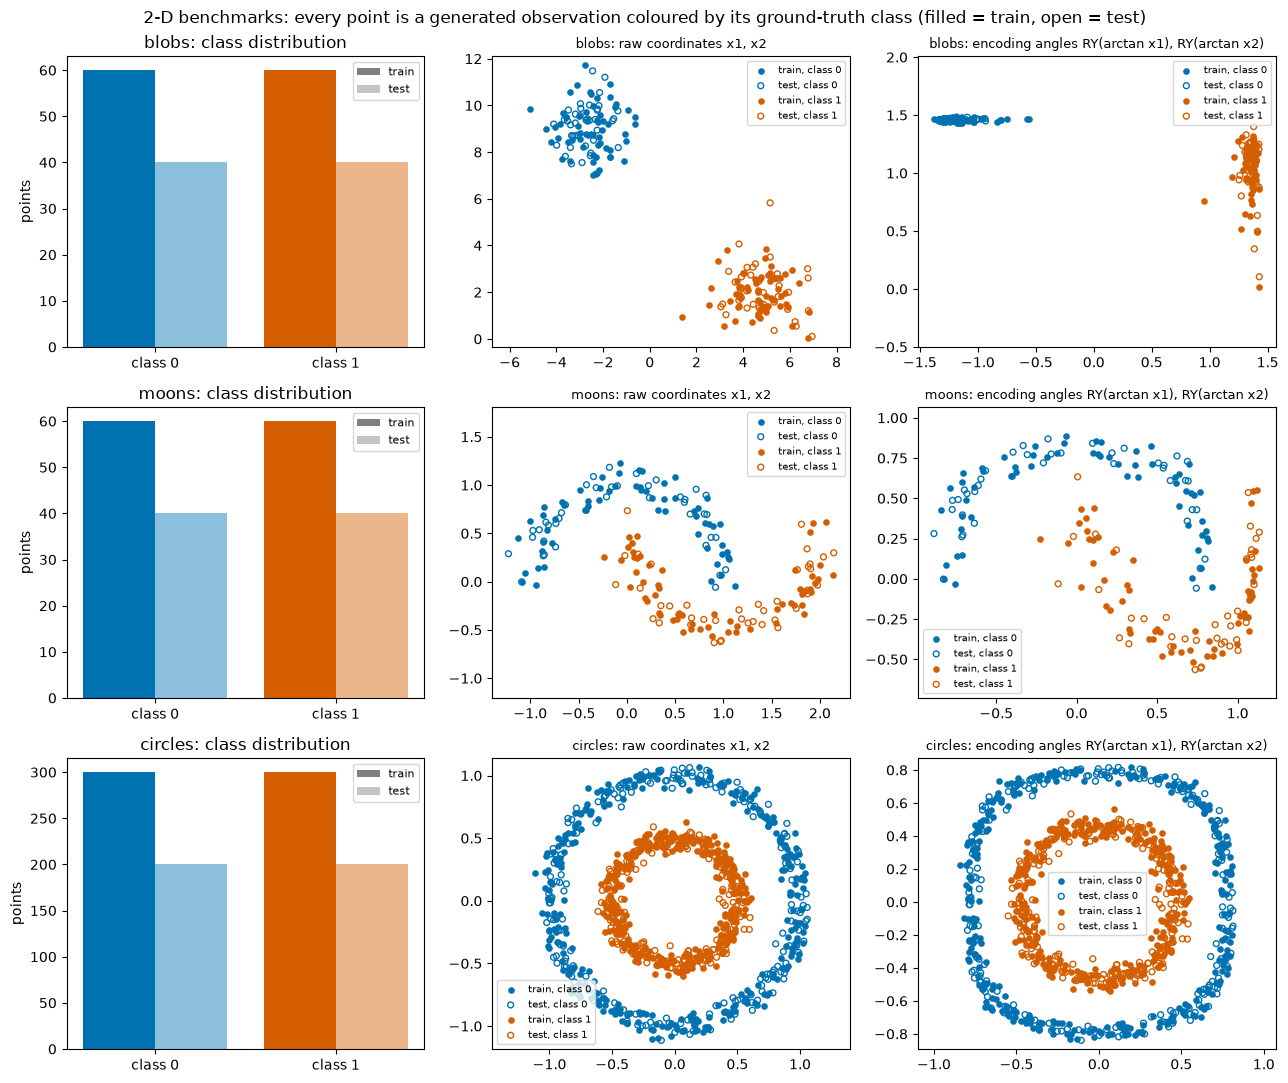

Here the 'PCA' of two features is just a rotation, so the raw coordinates are shown; the second column is the angle each qubit receives (paper Eq. 16: alpha = arctan x_i), which squeezes the plane into (-pi/2, pi/2) x (-pi/2, pi/2).


In [8]:
print("=== Dataset 2: the paper's three scikit-learn 2-D benchmarks (generated exactly as the paper does, with sklearn.datasets) ===")
fig, axs = plt.subplots(3, 3, figsize=(13, 11))
for r, name in enumerate(["blobs", "moons", "circles"]):
    Xtr, Xte, ytr, yte = TASKS2D[name]
    Xall = np.vstack([Xtr, Xte]); yall = np.concatenate([ytr, yte])
    print("%-8s shape %s | feature names ['x1', 'x2'] | label values %s counts %s | train %s test %s"
          % (name, Xall.shape, np.unique(yall).tolist(), np.bincount(yall).tolist(), Xtr.shape, Xte.shape))
    ax = axs[r, 0]
    for d in (0, 1):
        ax.bar(d - 0.2, int((ytr == d).sum()), 0.4, color=CLASS_COLORS[d])
        ax.bar(d + 0.2, int((yte == d).sum()), 0.4, color=CLASS_COLORS[d], alpha=0.45)
    ax.bar([-0.2], [0], 0.4, color="grey", label="train"); ax.bar([0.2], [0], 0.4, color="grey", alpha=0.45, label="test")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["class 0", "class 1"]); ax.set_ylabel("points"); ax.set_title("%s: class distribution" % name)
    ax.legend(fontsize=8)
    for k, (title, f) in enumerate([("raw coordinates x1, x2", lambda X: X),
                                    ("encoding angles RY(arctan x1), RY(arctan x2)", lambda X: np.arctan(X))]):
        ax = axs[r, k + 1]
        for d in (0, 1):
            ax.scatter(*f(Xtr)[ytr == d].T, s=14, color=CLASS_COLORS[d], label="train, class %d" % d)
            ax.scatter(*f(Xte)[yte == d].T, s=18, facecolors="none", edgecolors=CLASS_COLORS[d], label="test, class %d" % d)
        ax.set_title("%s: %s" % (name, title), fontsize=9); ax.set_aspect("equal", adjustable="datalim"); ax.legend(fontsize=7)
plt.suptitle("2-D benchmarks: every point is a generated observation coloured by its ground-truth class (filled = train, open = test)")
plt.tight_layout(); plt.show()
print("Here the 'PCA' of two features is just a rotation, so the raw coordinates are shown; the second column is the angle each qubit"
      " receives (paper Eq. 16: alpha = arctan x_i), which squeezes the plane into (-pi/2, pi/2) x (-pi/2, pi/2).")

## 2. An exact, fast simulator of the paper's circuits (and why it is allowed)

DP-SGD needs the gradient of the loss **for every single training example** (to clip it) and the model is evaluated tens of thousands
of times. Running one PennyLane QNode per example per parameter shift would take days on a CPU. The class below simulates the same
circuits exactly with NumPy:

* the state of the n-qubit register is a complex array; the n single-qubit rotations of a layer are applied as two small
  Kronecker-product matrices, which is mathematically the same unitary as n separate gates;
* the CNOT ring is a permutation of the amplitudes;
* gradients are exact **adjoint-differentiation** gradients, computed per sample (for a loss that depends on the circuit through
  expectation values sum_k c_k <Z_k>, one backward sweep gives the derivative with respect to all rotation angles). This is the analytic quantity
  that the parameter-shift rule in the paper estimates from two circuit evaluations per parameter.

A cell in the circuit-architecture section further below asserts that this simulator and the PennyLane QNodes give the same outputs and the
same gradients to 1e-10, so what is trained is what is drawn.

In [9]:
from functools import reduce

# ---- single-qubit gates -------------------------------------------------------------------------------------------
def rot_mat(phi, theta, omega):
    """Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi): the paper's Eq. (7) and PennyLane's qml.Rot, as a 2x2 matrix."""
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    a, b = (phi + omega) / 2, (phi - omega) / 2
    return np.array([[np.exp(-1j * a) * c, -np.exp(1j * b) * s],
                     [np.exp(-1j * b) * s, np.exp(1j * a) * c]])

def rot_generators(phi, theta, omega):
    """The three matrices G_k = (dRot/dp_k) Rot^dagger, p = (phi, theta, omega), from the analytic derivatives of Eq. (7)."""
    U = rot_mat(phi, theta, omega)
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    a, b = (phi + omega) / 2, (phi - omega) / 2
    d_theta = np.array([[-np.exp(-1j * a) * s / 2, -np.exp(1j * b) * c / 2],
                        [np.exp(-1j * b) * c / 2, -np.exp(1j * a) * s / 2]])
    d_phi = U * np.array([[-0.5j, 0.5j], [-0.5j, 0.5j]])
    d_omega = U * np.array([[-0.5j, -0.5j], [0.5j, 0.5j]])
    Ud = U.conj().T
    return d_phi @ Ud, d_theta @ Ud, d_omega @ Ud

def ry_batch(a):                                   # a: (B,) -> (B,2,2)
    c, s = np.cos(a / 2), np.sin(a / 2)
    U = np.zeros(a.shape + (2, 2), complex)
    U[..., 0, 0] = c; U[..., 0, 1] = -s; U[..., 1, 0] = s; U[..., 1, 1] = c
    return U

def rz_batch(b):
    U = np.zeros(b.shape + (2, 2), complex)
    U[..., 0, 0] = np.exp(-0.5j * b); U[..., 1, 1] = np.exp(0.5j * b)
    return U

PAULI_Y = np.array([[0, -1j], [1j, 0]]); PAULI_Z = np.array([[1, 0], [0, -1]], complex)

def cnot_ring_perm(n):
    """f[k] = basis state |k> is sent to by CNOT(0,1) CNOT(1,2) ... CNOT(n-1,0) applied in this order (wire 0 = most significant bit)."""
    f = np.arange(2 ** n)
    for c in range(n):
        t = (c + 1) % n
        f = f ^ (((f >> (n - 1 - c)) & 1) << (n - 1 - t))
    return f

def z_signs(n, wires):
    k = np.arange(2 ** n)
    return np.array([1 - 2 * ((k >> (n - 1 - w)) & 1) for w in wires], float)

# Architectures: (n_qubits, layers, n_outputs, encoding) for block 1 and block 2 of each task
SPEC = {"mnist": [(10, 8, 4, "amplitude"), (4, 4, 2, "angle")],
        "2d":    [(2, 2, 2, "angle"), (2, 2, 2, "angle")]}

class Block:
    """One variational block on n qubits: state preparation, then `layers` x (Rot on every wire, then a ring of CNOTs),
    read-out <Z> on wires 0 .. n_out-1.
      encoding='amplitude': the zero-padded, L2-normalised input vector is the initial state (paper Fig. 11)
      encoding='angle'    : wire i receives RY(arctan x_i) then RZ(arctan x_i^2) on |0>  (paper Eq. 16, Figs. 1, 6, 7, 12)
    The state is stored as an array (batch, 2**n1, 2**n2). The n rotations of a layer are applied as two small Kronecker-product
    matrices (one per half of the register): mathematically the same unitary as n separate one-qubit gates, just faster.
    Gradients are exact per-sample gradients from adjoint differentiation (no shot noise, no parameter shift)."""
    def __init__(self, n, layers, n_out, encoding):
        self.n, self.L, self.n_out, self.enc = n, layers, n_out, encoding
        self.n1 = n // 2; self.n2 = n - self.n1
        self.D1, self.D2 = 2 ** self.n1, 2 ** self.n2
        self.n_params = layers * n * 3
        self.perm = cnot_ring_perm(n); self.inv = np.argsort(self.perm)
        self.zs = z_signs(n, range(n_out))

    def _kron_halves(self, mats):
        return reduce(np.kron, mats[:self.n1]), reduce(np.kron, mats[self.n1:])

    def _apply(self, psi, K1, K2):
        B = psi.shape[0]
        t = (psi.reshape(B * self.D1, self.D2) @ K2.T).reshape(B, self.D1, self.D2)
        return np.matmul(K1, t)

    def _wire_reductions(self, lam, psi):
        """M_w[b,i,j] = sum over all other wires of conj(lam[..i..]) * psi[..j..], for every wire w (list of (B,2,2))."""
        B = psi.shape[0]; out = []
        R1 = np.matmul(lam.conj(), psi.transpose(0, 2, 1))
        R2 = np.matmul(lam.conj().transpose(0, 2, 1), psi)
        for w in range(self.n1):
            out.append(np.einsum("blirljr->bij", R1.reshape(B, 2 ** w, 2, 2 ** (self.n1 - w - 1), 2 ** w, 2, 2 ** (self.n1 - w - 1))))
        for w in range(self.n2):
            out.append(np.einsum("blirljr->bij", R2.reshape(B, 2 ** w, 2, 2 ** (self.n2 - w - 1), 2 ** w, 2, 2 ** (self.n2 - w - 1))))
        return out

    def _prepare(self, x):
        B = x.shape[0]
        if self.enc == "amplitude":
            v = np.zeros((B, 2 ** self.n)); v[:, :x.shape[1]] = x
            v /= np.linalg.norm(v, axis=1, keepdims=True)
            return v.astype(complex).reshape(B, self.D1, self.D2), None
        a, b = np.arctan(x), np.arctan(x ** 2)
        psi = np.zeros((B, 2 ** self.n), complex); psi[:, 0] = 1
        for w in range(self.n):
            E = rz_batch(b[:, w]) @ ry_batch(a[:, w])
            psi = np.einsum("bij,bljr->blir", E, psi.reshape(B, 2 ** w, 2, 2 ** (self.n - w - 1))).reshape(B, -1)
        return psi.reshape(B, self.D1, self.D2), (a, b)

    def forward(self, theta, x, keep=False):
        th = theta.reshape(self.L, self.n, 3); B = x.shape[0]
        psi, ab = self._prepare(x); Ks = []
        for l in range(self.L):
            mats = [rot_mat(*th[l, w]) for w in range(self.n)]
            K1, K2 = self._kron_halves(mats); Ks.append(mats)
            psi = self._apply(psi, K1, K2)
            psi = psi.reshape(B, -1)[:, self.inv].reshape(B, self.D1, self.D2)       # CNOT ring: psi_new[f[k]] = psi[k]
        z = (np.abs(psi.reshape(B, -1)) ** 2) @ self.zs.T
        return (z, (psi, ab, Ks)) if keep else z

    def backward(self, theta, tape, c):
        """For each sample b the scalar f_b = sum_k c[b,k] <Z_k>. Returns its exact gradient w.r.t. all rotation angles (B, n_params)
        and, for angle encoding, w.r.t. the two encoding angles of every wire, (d/d arctan x_i, d/d arctan x_i^2), each (B, n)."""
        psi, ab, Ks = tape; n = self.n; B = psi.shape[0]
        th = theta.reshape(self.L, n, 3)
        lam = ((c @ self.zs).reshape(B, self.D1, self.D2)) * psi        # O |psi_final>, O = sum_k c_k Z_k
        g = np.zeros((B, self.L, n, 3))
        for l in range(self.L - 1, -1, -1):
            psi = psi.reshape(B, -1)[:, self.perm].reshape(B, self.D1, self.D2)       # undo the CNOT ring
            lam = lam.reshape(B, -1)[:, self.perm].reshape(B, self.D1, self.D2)
            Ms = self._wire_reductions(lam, psi)
            for w in range(n):
                for k, G in enumerate(rot_generators(*th[l, w])):
                    g[:, l, w, k] = 2 * np.real(np.einsum("ij,bij->b", G, Ms[w]))
            K1, K2 = self._kron_halves([m.conj().T for m in Ks[l]])
            psi = self._apply(psi, K1, K2); lam = self._apply(lam, K1, K2)
        gx = None
        if self.enc == "angle":
            a, b = ab
            Ms = self._wire_reductions(lam, psi)
            ga = np.zeros((B, n)); gb = np.zeros((B, n))
            for w in range(n):
                gb[:, w] = 2 * np.real(np.einsum("ij,bij->b", -0.5j * PAULI_Z, Ms[w]))
                R = rz_batch(b[:, w])
                Ga = R @ (-0.5j * PAULI_Y) @ R.conj().transpose(0, 2, 1)
                ga[:, w] = 2 * np.real(np.einsum("bij,bij->b", Ga, Ms[w]))
            gx = (ga, gb)
        return g.reshape(B, -1), gx

## Quantum Circuit Architecture

The hybrid model has two circuit blocks (paper Figs. 1, 6, 7, 11, 12). Each block is

* **state preparation**: *amplitude encoding* of a 1024-vector on 10 qubits (MNIST block 1), or *variational encoding* RY(arctan x_i) then
  RZ(arctan x_i^2) on every qubit (Eq. 16; 2-D blocks and MNIST block 2, the inputs of block 2 being the outputs of block 1);
* **layers**: each layer applies the general rotation Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) (Eq. 7, three trainable angles) to
  every qubit followed by CNOT gates that entangle the qubits;
* **read-out**: the expectation value of sigma_z on the first few qubits.

Architectures: 2-D tasks, two identical blocks of 2 qubits and 2 layers (12 parameters each); MNIST block 1: 10 qubits, 8 layers, 4 outputs
(8 x 10 x 3 = 240 parameters); MNIST block 2: 4 qubits, 4 layers, 2 outputs (4 x 4 x 3 = 48 parameters).

**Assumptions where the paper's figures leave details open** (they are drawings, not code): (i) the CNOT pattern inside one layer; a **ring**
CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) is used (for two qubits CNOT(0,1) followed by CNOT(1,0)); (ii) the read-out qubits are the first
n_out wires; (iii) amplitude encoding is exact state preparation (the paper treats it as given and does not count its gate cost); (iv) the
trainable angles start at 0.01 N(0,1), so every circuit starts almost at the identity (plus the CNOT ring).

In [10]:
import pennylane as qml
from pennylane import numpy as pnp

def make_qnode(n, layers, n_out, encoding):
    """The PennyLane QNode of one block: exactly the circuit of the paper's Figs. 1, 6, 7, 11, 12 (with the entangler CHOSEN as a CNOT ring)."""
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="autograd")
    def circuit(x, w):
        if encoding == "amplitude":                                   # Fig. 11: U(x), amplitude encoding of 1024 numbers on 10 qubits
            qml.AmplitudeEmbedding(x, wires=range(n), pad_with=0.0, normalize=True)
        else:                                                         # Eq. (16): R_i(x) = RZ(arctan x_i^2) RY(arctan x_i)
            for i in range(n):
                qml.RY(pnp.arctan(x[i]), wires=i)
                qml.RZ(pnp.arctan(x[i] ** 2), wires=i)
        for l in range(layers):                                       # one dashed box = Rot on every wire + entangling CNOTs
            for q in range(n):
                qml.Rot(w[l, q, 0], w[l, q, 1], w[l, q, 2], wires=q)
            for q in range(n):                                        # CHOICE: ring CNOT(q, q+1 mod n)
                qml.CNOT(wires=[q, (q + 1) % n])
        return [qml.expval(qml.PauliZ(k)) for k in range(n_out)]      # <sigma_z> on the first n_out wires
    return circuit

def draw_chunks(qnode, args, parts, title):
    """qml.draw_mpl of the executed QNode, cut into `parts` horizontal pieces so that long circuits stay readable."""
    fig, ax = qml.draw_mpl(qnode, decimals=2)(*args)
    W, H = fig.get_size_inches(); x0, x1 = ax.get_xlim(); plt.close(fig)
    for k in range(parts):
        fig, ax = qml.draw_mpl(qnode, decimals=2)(*args)
        lo, hi = x0 + (x1 - x0) * k / parts, x0 + (x1 - x0) * (k + 1) / parts
        ax.set_xlim(lo, hi); fig.set_size_inches(W / parts, H)
        ax.set_title("%s (part %d of %d)" % (title, k + 1, parts) if parts > 1 else title, fontsize=11)
        plt.show()

The two model classes below are the **hybrid VQC** (block 1, block 2, softmax cross-entropy) and the **classical control** of the paper's
Fig. 4 (Linear - tanh - Linear - tanh - softmax). Both return exact per-sample gradients, which is what DP-SGD clips.

In [11]:
def softmax(a):
    e = np.exp(a - a.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

class HybridVQC:
    """The paper's hybrid model: block 1 -> <Z> values -> block 2 (variational angle encoding of those values) -> 2 logits -> softmax
    cross-entropy. kind='2d': two blocks of 2 qubits, 2 layers each (2 x 12 = 24 parameters).
    kind='mnist': block 1 = 10 qubits, amplitude encoding, 8 layers, 4 outputs (240 parameters); block 2 = 4 qubits, angle
    encoding, 4 layers, 2 outputs (48 parameters); 288 in total."""
    def __init__(self, kind):
        self.kind = kind
        self.b1, self.b2 = (Block(*s) for s in SPEC[kind])
        self.n_params = self.b1.n_params + self.b2.n_params

    def init(self, rng):                              # paper: N(0, 1) scaled by 0.01
        return 0.01 * rng.standard_normal(self.n_params)

    def split(self, theta):
        return theta[:self.b1.n_params], theta[self.b1.n_params:]

    def logits(self, theta, X):
        t1, t2 = self.split(theta)
        return self.b2.forward(t2, self.b1.forward(t1, X))

    def predict(self, theta, X, chunk=500):
        return np.concatenate([self.logits(theta, X[i:i + chunk]).argmax(1) for i in range(0, len(X), chunk)])

    def per_sample_grads(self, theta, X, y):
        t1, t2 = self.split(theta)
        z1, tape1 = self.b1.forward(t1, X, keep=True)
        z2, tape2 = self.b2.forward(t2, z1, keep=True)
        p = softmax(z2); c2 = p.copy(); c2[np.arange(len(y)), y] -= 1.0           # dL/d logits
        g2, (ga, gb) = self.b2.backward(t2, tape2, c2)
        c1 = ga / (1 + z1 ** 2) + gb * 2 * z1 / (1 + z1 ** 4)                       # chain rule through arctan(z) and arctan(z^2)
        g1, _ = self.b1.backward(t1, tape1, c1)
        return np.concatenate([g1, g2], axis=1), -np.log(p[np.arange(len(y)), y] + 1e-12)

class TanhNet:
    """The paper's classical control: Linear -> tanh -> Linear -> tanh -> softmax (Fig. 4). Xavier-uniform weights, zero biases."""
    def __init__(self, d_in, hidden):
        self.d, self.h = d_in, hidden
        self.n_params = d_in * hidden + hidden + hidden * 2 + 2

    def init(self, rng):
        lim1 = np.sqrt(6 / (self.d + self.h)); lim2 = np.sqrt(6 / (self.h + 2))
        return np.concatenate([rng.uniform(-lim1, lim1, self.d * self.h), np.zeros(self.h),
                               rng.uniform(-lim2, lim2, self.h * 2), np.zeros(2)])

    def unpack(self, th):
        d, h = self.d, self.h
        W1 = th[:d * h].reshape(d, h); b1 = th[d * h:d * h + h]
        W2 = th[d * h + h:d * h + h + 2 * h].reshape(h, 2); b2 = th[-2:]
        return W1, b1, W2, b2

    def logits(self, th, X):
        W1, b1, W2, b2 = self.unpack(th)
        return np.tanh(np.tanh(X @ W1 + b1) @ W2 + b2)

    def predict(self, th, X):
        return self.logits(th, X).argmax(1)

    def per_sample_grads(self, th, X, y):
        W1, b1, W2, b2 = self.unpack(th); B = len(y)
        a1 = np.tanh(X @ W1 + b1); a2 = np.tanh(a1 @ W2 + b2)
        p = softmax(a2); d2 = p.copy(); d2[np.arange(B), y] -= 1.0
        dz2 = d2 * (1 - a2 ** 2)
        gW2 = a1[:, :, None] * dz2[:, None, :]
        dz1 = (dz2 @ W2.T) * (1 - a1 ** 2)
        gW1 = X[:, :, None] * dz1[:, None, :]
        G = np.concatenate([gW1.reshape(B, -1), dz1, gW2.reshape(B, -1), dz2], axis=1)
        return G, -np.log(p[np.arange(B), y] + 1e-12)

### The simulator is the drawn circuit

The next cell builds the PennyLane QNode of every block (these are the objects drawn below) and checks, on random parameters and on real data
points, that (a) the outputs and (b) the exact per-sample gradients of the simulator equal PennyLane's (automatic differentiation through the
QNode), for each block and for the whole two-block model including the arctan hand-over between the blocks. The assertions fail the notebook if
they are not equal to 1e-10.

In [12]:
# The executed model is the NumPy simulator of Section 2; the circuits drawn below are the PennyLane QNodes. This cell asserts that the
# two are the same function: same outputs, and same exact gradients (autograd back-propagation through the QNodes), on random
# parameters (a harder test than the near-zero training initialisation) and on real data points.
def check_block(spec, X, label):
    n, L, n_out, enc = spec
    blk = Block(*spec); rng_t = np.random.default_rng(7)
    th = rng_t.normal(0, 1.0, blk.n_params); qn = make_qnode(*spec)
    z, tape = blk.forward(th, X, keep=True)
    zq = np.array([np.array(qn(pnp.array(x, requires_grad=False), pnp.array(th.reshape(L, n, 3), requires_grad=False))) for x in X])
    c = rng_t.normal(size=(len(X), n_out)); g, _ = blk.backward(th, tape, c)
    err_g = 0.0
    for b in range(len(X)):
        f = lambda w: pnp.sum(pnp.array(c[b]) * pnp.stack(qn(pnp.array(X[b], requires_grad=False), w)))
        gw = qml.grad(f, argnums=0)(pnp.array(th.reshape(L, n, 3), requires_grad=True))
        err_g = max(err_g, float(np.abs(np.array(gw).reshape(-1) - g[b]).max()))
    err_f = float(np.abs(z - zq).max())
    print("%-34s outputs: max|simulator - QNode| = %.1e | per-sample gradients: max|diff| = %.1e" % (label, err_f, err_g))
    assert err_f < 1e-10 and err_g < 1e-10, "simulator and QNode disagree"

check_block(SPEC["2d"][0], TASKS2D["moons"][0][:3], "2-D block (2 qubits, 2 layers)")
check_block(SPEC["mnist"][1], np.random.default_rng(3).normal(0, 1.5, (3, 4)), "MNIST block 2 (4 qubits, 4 layers)")
check_block(SPEC["mnist"][0], mn_Xtr[:2], "MNIST block 1 (10 qubits, 8 layers)")

def hybrid_loss_qnode(theta, x, y, kind):
    (s1, s2) = SPEC[kind]; q1, q2 = make_qnode(*s1), make_qnode(*s2)
    n1p = s1[0] * s1[1] * 3
    z = pnp.stack(q1(x, theta[:n1p].reshape(s1[1], s1[0], 3)))
    out = pnp.stack(q2(z, theta[n1p:].reshape(s2[1], s2[0], 3)))
    p = pnp.exp(out - pnp.max(out)) / pnp.sum(pnp.exp(out - pnp.max(out)))
    return -pnp.log(p[y])

for kind, Xs, ys in [("2d", TASKS2D["circles"][0][:2], TASKS2D["circles"][2][:2]), ("mnist", mn_Xtr[:2], mn_ytr[:2])]:
    model = HybridVQC(kind); th = np.random.default_rng(11).normal(0, 0.8, model.n_params)
    G, loss = model.per_sample_grads(th, Xs, ys); err = 0.0
    for b in range(len(ys)):
        gq = qml.grad(lambda t: hybrid_loss_qnode(t, pnp.array(Xs[b], requires_grad=False), int(ys[b]), kind))(pnp.array(th, requires_grad=True))
        err = max(err, float(np.abs(np.array(gq) - G[b]).max()))
    print("hybrid model '%s' (%d parameters): max|per-sample loss gradient, simulator - QNode autograd| = %.1e" % (kind, model.n_params, err))
    assert err < 1e-9

2-D block (2 qubits, 2 layers)     outputs: max|simulator - QNode| = 6.7e-16 | per-sample gradients: max|diff| = 4.4e-16


MNIST block 2 (4 qubits, 4 layers) outputs: max|simulator - QNode| = 4.2e-16 | per-sample gradients: max|diff| = 7.8e-16


MNIST block 1 (10 qubits, 8 layers) outputs: max|simulator - QNode| = 1.9e-16 | per-sample gradients: max|diff| = 3.7e-16
hybrid model '2d' (24 parameters): max|per-sample loss gradient, simulator - QNode autograd| = 6.1e-16


hybrid model 'mnist' (288 parameters): max|per-sample loss gradient, simulator - QNode autograd| = 2.8e-16


### The circuits that are executed

Drawings of the QNodes (`qml.draw_mpl`). Each shows the state preparation, the parametrised Rot gates (the numbers are the angles of the example
input and 0.01-scaled initial weights), the CNOT ring and the sigma_z read-outs. The 10-qubit circuit is wide, so it is cut into four consecutive
parts (two layers each).

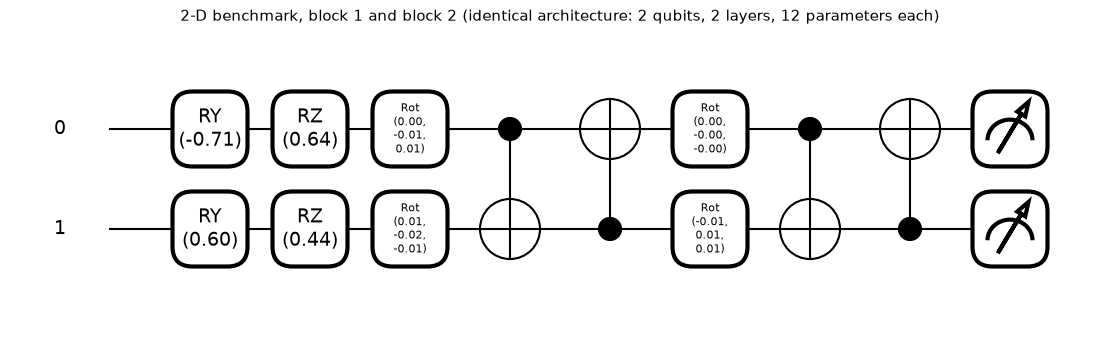

In [13]:
args2 = (pnp.array(TASKS2D["moons"][0][0], requires_grad=False), pnp.array(0.01 * np.random.default_rng(SEED).standard_normal((2, 2, 3))))
qn_2d = make_qnode(*SPEC["2d"][0])
draw_chunks(qn_2d, args2, 1, "2-D benchmark, block 1 and block 2 (identical architecture: 2 qubits, 2 layers, 12 parameters each)")

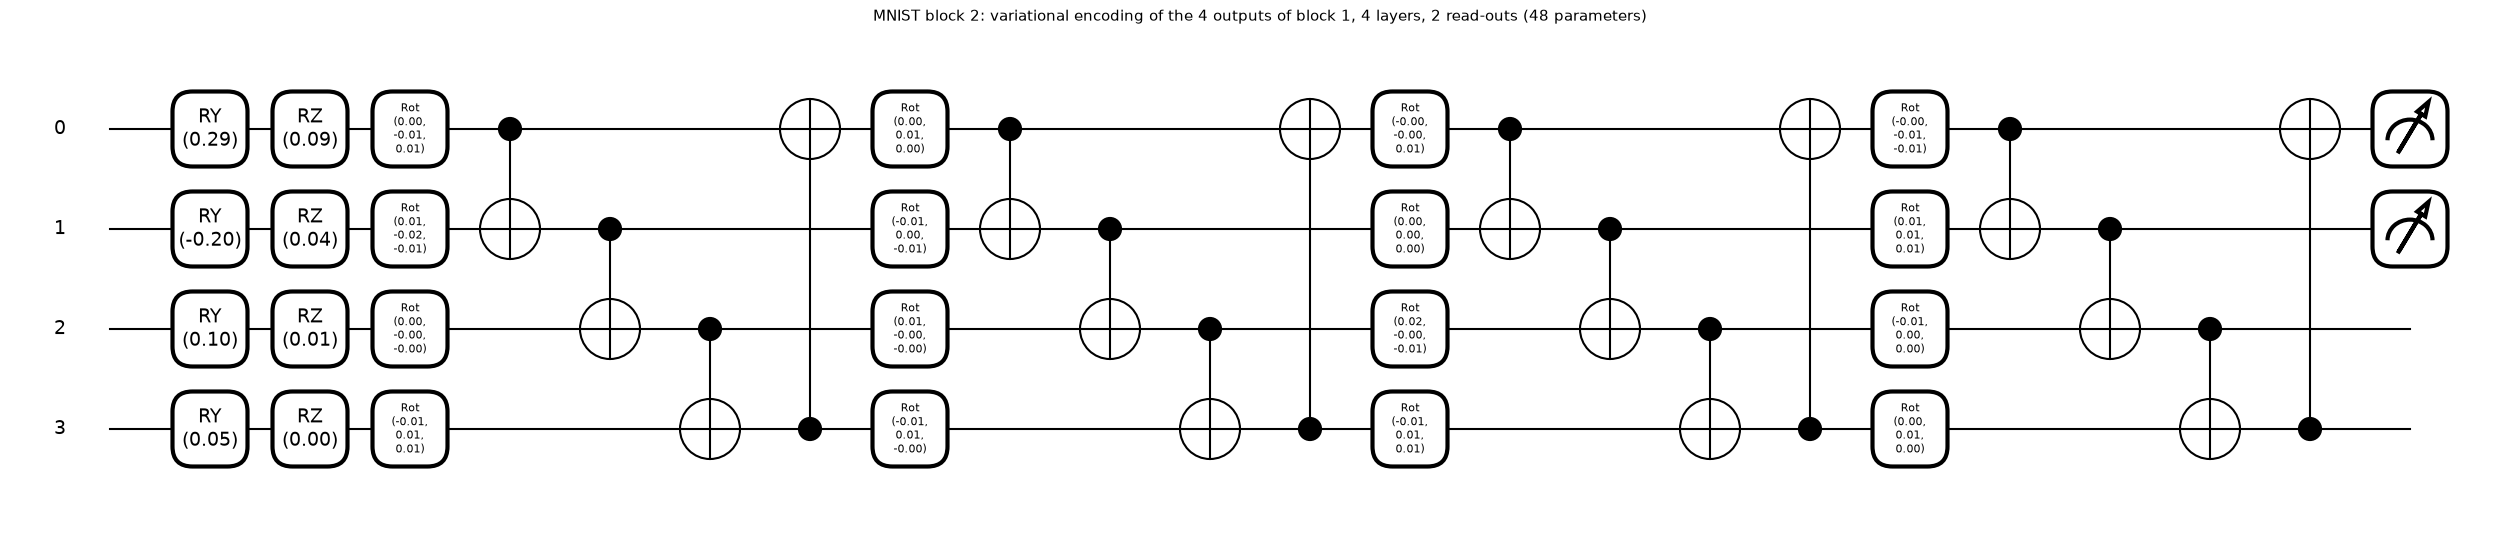

In [14]:
args_m2 = (pnp.array([0.3, -0.2, 0.1, 0.05], requires_grad=False), pnp.array(0.01 * np.random.default_rng(SEED).standard_normal((4, 4, 3))))
qn_m2 = make_qnode(*SPEC["mnist"][1])
draw_chunks(qn_m2, args_m2, 1, "MNIST block 2: variational encoding of the 4 outputs of block 1, 4 layers, 2 read-outs (48 parameters)")

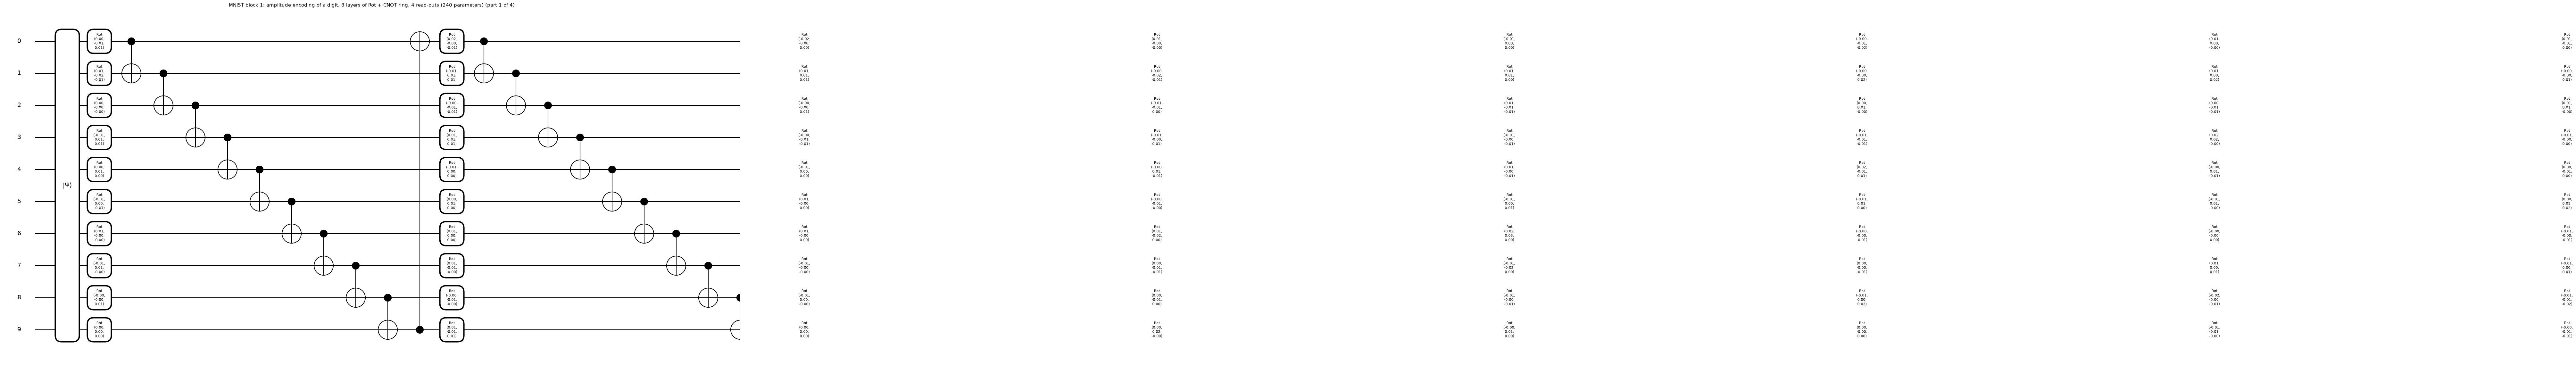

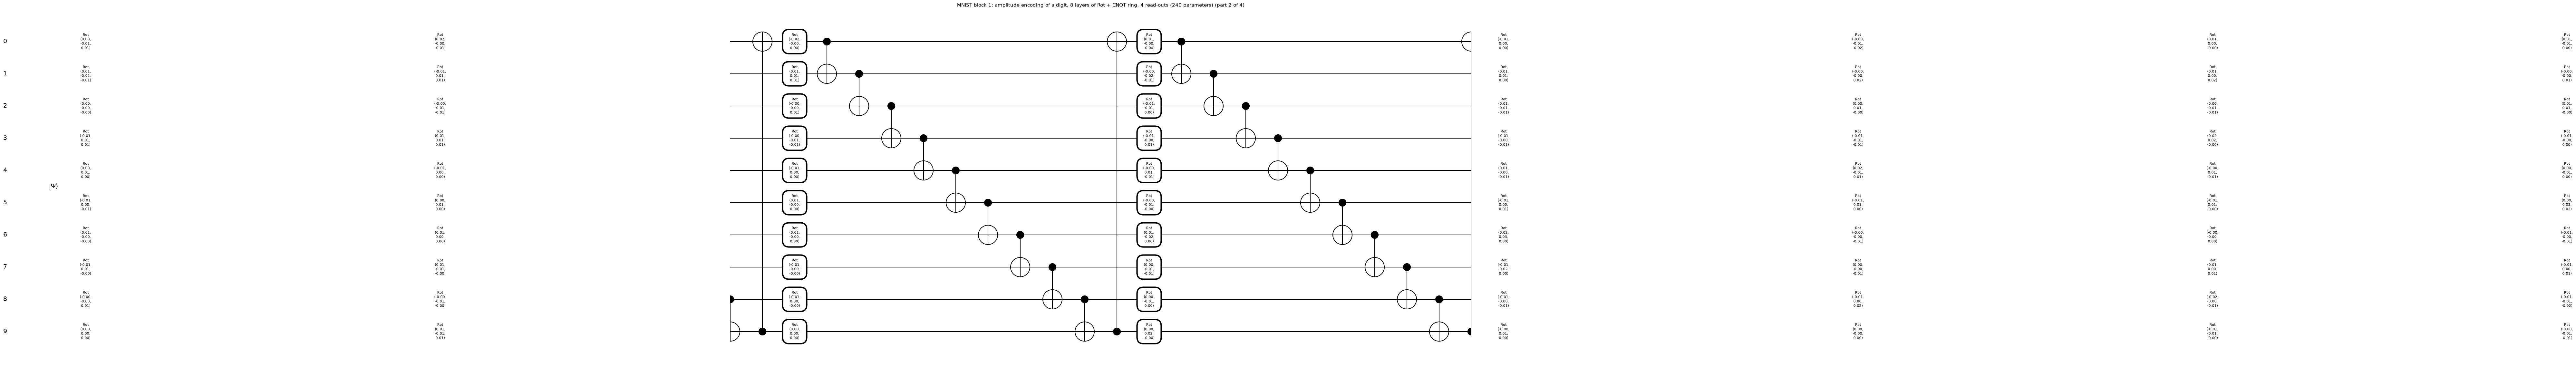

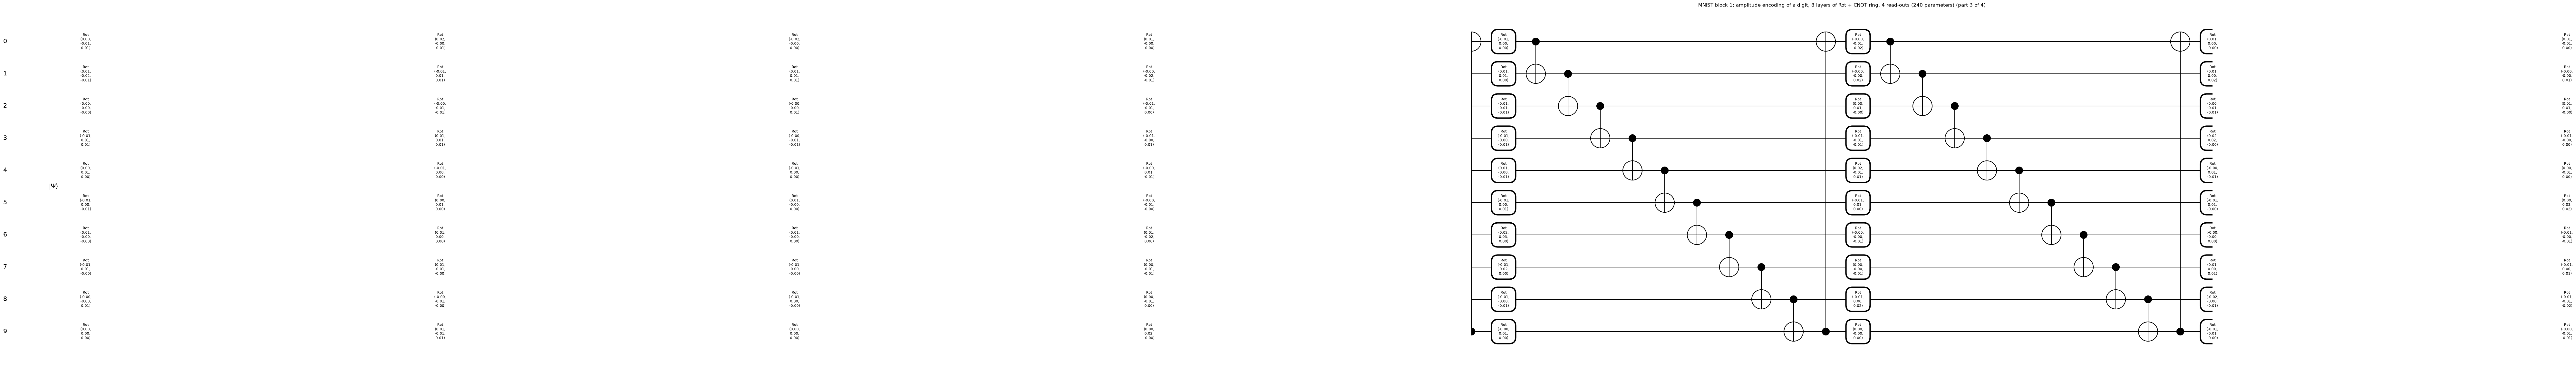

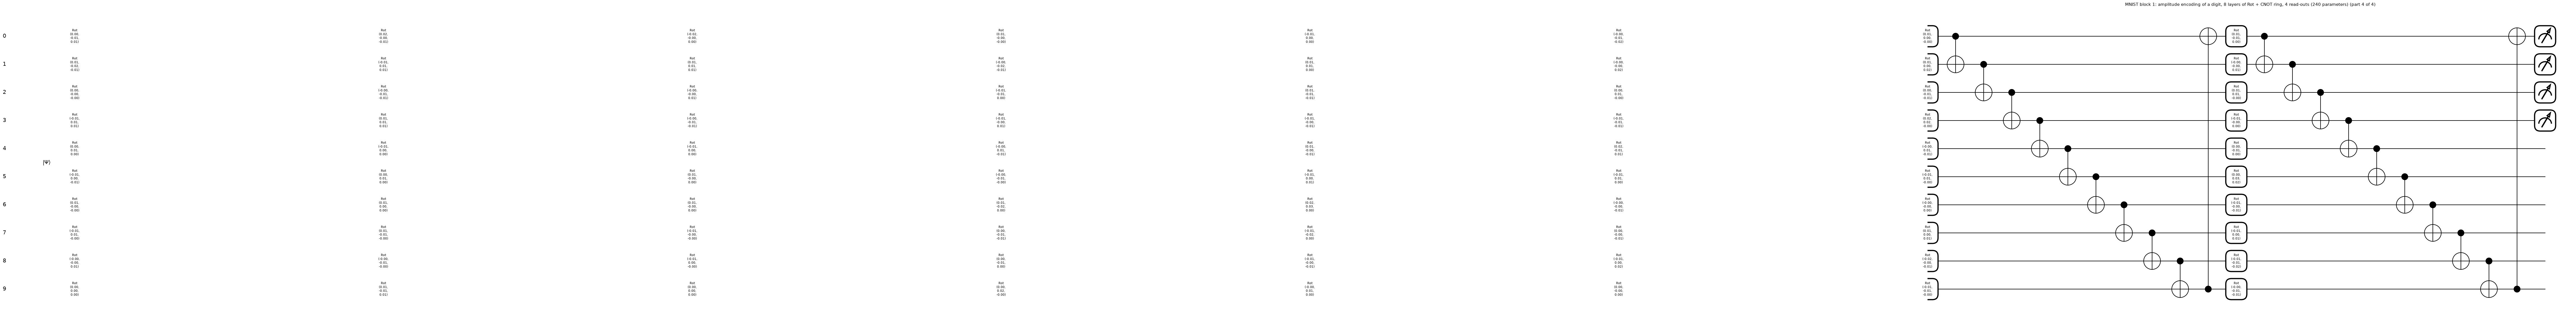

In [15]:
args_m1 = (pnp.array(mn_Xtr[0], requires_grad=False), pnp.array(0.01 * np.random.default_rng(SEED).standard_normal((8, 10, 3))))
qn_m1 = make_qnode(*SPEC["mnist"][0])
draw_chunks(qn_m1, args_m1, 4, "MNIST block 1: amplitude encoding of a digit, 8 layers of Rot + CNOT ring, 4 read-outs (240 parameters)")

In [16]:
rows = []
for name, qn, a, spec, extra in [("2-D block (x2)", qn_2d, args2, SPEC["2d"][0], 2), ("MNIST block 1", qn_m1, args_m1, SPEC["mnist"][0], 1),
                                 ("MNIST block 2", qn_m2, args_m2, SPEC["mnist"][1], 1)]:
    sp = qml.specs(qn)(*a)
    rows.append({"architecture": name, "qubits": spec[0], "layers": spec[1], "depth (qml.specs)": sp.resources.depth,
                 "gates": dict(sp.resources.gate_types), "trainable parameters": spec[0] * spec[1] * 3, "read-out <Z> on wires": list(range(spec[2]))})
    assert spec[0] * spec[1] * 3 == Block(*spec).n_params
print(pd.DataFrame(rows).to_string(index=False))
print("\nWhole models: 2-D hybrid = %d trainable parameters (paper: 24); MNIST hybrid = %d (paper: 288 = 240 + 48)."
      % (HybridVQC("2d").n_params, HybridVQC("mnist").n_params))
print("Chain: image -> [block 1 on 10 qubits] -> 4 expectation values z -> angles arctan(z), arctan(z^2) -> [block 2 on 4 qubits] -> 2 values -> softmax cross-entropy.")

  architecture  qubits  layers  depth (qml.specs)                                            gates  trainable parameters read-out <Z> on wires
2-D block (x2)       2       2                  8          {'RY': 2, 'RZ': 2, 'Rot': 4, 'CNOT': 4}                    12                [0, 1]
 MNIST block 1      10       8                 89 {'AmplitudeEmbedding': 1, 'Rot': 80, 'CNOT': 80}                   240          [0, 1, 2, 3]
 MNIST block 2       4       4                 22        {'RY': 4, 'RZ': 4, 'Rot': 16, 'CNOT': 16}                    48                [0, 1]

Whole models: 2-D hybrid = 24 trainable parameters (paper: 24); MNIST hybrid = 288 (paper: 288 = 240 + 48).
Chain: image -> [block 1 on 10 qubits] -> 4 expectation values z -> angles arctan(z), arctan(z^2) -> [block 2 on 4 qubits] -> 2 values -> softmax cross-entropy.


## 3. DP-SGD, RMSprop and the privacy accountant

**DP-SGD (Abadi et al., 2016).** For a mini-batch B drawn at sampling rate q = 32 / N: compute the gradient g_i of every sample i, clip it to
g_i * min(1, S / ||g_i||), sum, add N(0, sigma^2 S^2 I) and divide by the batch size. The paper writes this for the batch gradient in its
Eqs. (14a) and (18); the privacy accounting it relies on (PyVacy) is that of per-example clipping, which is what is implemented here.

**Privacy accountant.** One DP-SGD step is a "sampled Gaussian mechanism". Its Renyi-DP at integer order a is

RDP(a) = (1 / (a - 1)) * ln sum_k C(a, k) (1 - q)^(a - k) q^k exp((k^2 - k) / (2 sigma^2)),

RDP adds up over steps, and (epsilon, delta)-DP follows from epsilon = min over a of [ RDP(a) - ln(delta) / (a - 1) ] (the conversion of the
2019-era TF-Privacy / PyVacy code; the tighter conversion of Balle et al. 2020 is available as `conversion="modern"`). The cells below test every
building block, including the accountant against a published number.

In [17]:
from scipy.special import logsumexp, gammaln
from scipy.optimize import brentq

# ---- Renyi-DP accountant for the sampled Gaussian mechanism (Mironov, Talwar, Zhang 2019), integer orders --------------
ORDERS = np.concatenate([np.arange(2, 65), [72, 80, 96, 128, 192, 256, 512]]).astype(int)

def rdp_sampled_gaussian(q, sigma, steps, orders=ORDERS):
    """RDP of `steps` compositions of one DP-SGD step with sampling rate q and noise multiplier sigma."""
    out = []
    for a in orders:
        k = np.arange(a + 1)
        log_binom = gammaln(a + 1) - gammaln(k + 1) - gammaln(a - k + 1)
        log_terms = log_binom + k * np.log(q) + (a - k) * np.log1p(-q) + (k * k - k) / (2 * sigma ** 2)
        out.append(logsumexp(log_terms) / (a - 1))
    return np.array(out) * steps

def epsilon(N, batch, sigma, steps, delta=1e-5, conversion="abadi"):
    """(eps, delta)-DP of `steps` DP-SGD iterations on N samples, expected batch size `batch`.
    conversion='abadi'  : eps = min_a [ RDP(a) - ln(delta)/(a-1) ]     (the 2019-era conversion used by TF-Privacy / PyVacy)
    conversion='modern' : eps = min_a [ RDP(a) + ln(1-1/a) - (ln(delta)+ln(a))/(a-1) ]   (Balle et al. 2020, tighter)"""
    r = rdp_sampled_gaussian(min(batch / N, 1.0), sigma, steps)
    if conversion == "abadi":
        e = r - np.log(delta) / (ORDERS - 1)
    else:
        e = r + np.log1p(-1 / ORDERS) - (np.log(delta) + np.log(ORDERS)) / (ORDERS - 1)
    return float(e.min())

def sigma_for_epsilon(target, N, batch, steps, delta=1e-5, conversion="abadi"):
    """Invert epsilon(): the noise multiplier that gives exactly `target`."""
    return brentq(lambda s: epsilon(N, batch, s, steps, delta, conversion) - target, 0.2, 200.0, xtol=1e-6)

# ---- DP-SGD building blocks ----------------------------------------------------------------------------------------
def dp_gradient(G, clip, sigma, expected_batch, rng):
    """G: per-sample gradients (m, P). Clip each row to L2 norm <= clip, sum, add N(0, (sigma*clip)^2) to every coordinate,
    divide by the expected batch size (Abadi et al. 2016, Algorithm 1; what PyVacy's DP optimisers do)."""
    norms = np.linalg.norm(G, axis=1)
    scale = np.minimum(1.0, clip / (norms + 1e-6))
    return ((G * scale[:, None]).sum(axis=0) + rng.normal(0.0, sigma * clip, G.shape[1])) / expected_batch

class RMSprop:
    """torch.optim.RMSprop semantics (alpha=0.9, eps=1e-8, momentum=0.5, no weight decay, not centred)."""
    def __init__(self, n, lr=0.05, alpha=0.9, eps=1e-8, momentum=0.5):
        self.lr, self.alpha, self.eps, self.mom = lr, alpha, eps, momentum
        self.sq = np.zeros(n); self.buf = np.zeros(n)
    def step(self, theta, g):
        self.sq = self.alpha * self.sq + (1 - self.alpha) * g * g
        self.buf = self.mom * self.buf + g / (np.sqrt(self.sq) + self.eps)
        return theta - self.lr * self.buf

def train(model, theta, Xtr, ytr, Xte, yte, *, epochs, rng, dp, sigma=0.0, clip=1.0, batch=32, iters_per_epoch=None,
          lr=0.05, eval_epochs=(), log=None):
    """Mini-batch training with RMSprop. dp=False: reshuffled full passes (ceil(N/batch) steps per epoch).
    dp=True : DP-SGD; every 'epoch' is `iters_per_epoch` iterations, each on a Poisson-sampled mini-batch (every sample is
              included independently with probability batch/N), per-sample clipping and Gaussian noise (see dp_gradient)."""
    N = len(ytr); opt = RMSprop(theta.size, lr=lr); hist = {"epoch": [], "train_loss": [], "test_acc": [], "test_epoch": []}
    steps = 0
    for ep in range(1, epochs + 1):
        losses = []
        if dp:
            batches = (np.flatnonzero(rng.random(N) < batch / N) for _ in range(iters_per_epoch))
        else:
            perm = rng.permutation(N); batches = (perm[i:i + batch] for i in range(0, N, batch))
        for idx in batches:
            if idx.size == 0:
                continue
            G, loss = model.per_sample_grads(theta, Xtr[idx], ytr[idx])
            g = dp_gradient(G, clip, sigma, batch, rng) if dp else G.mean(axis=0)
            theta = opt.step(theta, g); steps += 1; losses.append(loss.mean())
        hist["epoch"].append(ep); hist["train_loss"].append(float(np.mean(losses)) if losses else np.nan)
        if ep in eval_epochs or ep == epochs:
            hist["test_epoch"].append(ep); hist["test_acc"].append(float((model.predict(theta, Xte) == yte).mean()))
    hist["steps"] = steps
    return theta, hist

In [18]:
# ---- unit tests of the DP machinery (every assertion must hold, otherwise the cell fails) ----
rt = np.random.default_rng(0)
# 1) no noise and a huge clip: DP-SGD must reduce to the plain mini-batch mean gradient
G = rt.normal(size=(32, 50)) * rt.uniform(0.1, 5.0, size=(32, 1))
assert np.allclose(dp_gradient(G, 1e9, 0.0, 32, rt), G.mean(axis=0))
# 2) clipping: after clipping every per-sample gradient has norm <= S, and short gradients are left untouched
scale = np.minimum(1.0, 1.5 / (np.linalg.norm(G, axis=1) + 1e-6))
assert np.all(np.linalg.norm(G * scale[:, None], axis=1) <= 1.5 + 1e-6)
assert np.allclose((G * scale[:, None])[np.linalg.norm(G, axis=1) < 1.4], G[np.linalg.norm(G, axis=1) < 1.4], atol=1e-5)
# 3) noise: with zero gradients the output is pure noise of standard deviation sigma * S / batch
z = dp_gradient(np.zeros((32, 400_000)), 1.5, 2.0, 32, rt)
print("empirical noise std %.5f vs expected sigma*S/batch = %.5f" % (z.std(), 2.0 * 1.5 / 32)); assert abs(z.std() / (2.0 * 1.5 / 32) - 1) < 0.01
# 4) RMSprop follows torch.optim.RMSprop(lr, alpha=0.9, eps=1e-8, momentum=0.5): hand-computed first two steps
o = RMSprop(1, lr=0.05); t1 = o.step(np.array([1.0]), np.array([2.0])); t2 = o.step(t1, np.array([1.0]))
sq1 = 0.1 * 4.0; b1 = 2.0 / (np.sqrt(sq1) + 1e-8); sq2 = 0.9 * sq1 + 0.1 * 1.0; b2 = 0.5 * b1 + 1.0 / (np.sqrt(sq2) + 1e-8)
assert np.allclose(t1, 1.0 - 0.05 * b1) and np.allclose(t2, t1 - 0.05 * b2)
# 5) per-sample gradients of the classical net against finite differences; and of the hybrid VQC (2-D) against finite differences
for model, X, y in [(TanhNet(2, 7), TASKS2D["moons"][0][:3], TASKS2D["moons"][2][:3]), (HybridVQC("2d"), TASKS2D["moons"][0][:3], TASKS2D["moons"][2][:3])]:
    th = np.random.default_rng(5).normal(0, 0.7, model.n_params); G, loss = model.per_sample_grads(th, X, y)
    fd = np.zeros_like(G); h = 1e-6
    for j in range(model.n_params):
        e = np.zeros(model.n_params); e[j] = h
        fd[:, j] = (model.per_sample_grads(th + e, X, y)[1] - model.per_sample_grads(th - e, X, y)[1]) / (2 * h)
    print("%-10s per-sample gradient vs central finite differences: max|diff| = %.1e" % (type(model).__name__, np.abs(G - fd).max()))
    assert np.abs(G - fd).max() < 1e-6
# 6) the accountant against a published number: TF-Privacy reports eps = 3.01 for N=60000, batch 256, sigma 1.1, 60 epochs, delta 1e-5
e_tf = epsilon(60000, 256, 1.1, int(60 * 60000 / 256), 1e-5)
print("accountant on the TF-Privacy MNIST example: eps = %.2f (published: 3.01)" % e_tf); assert abs(e_tf - 3.01) < 0.02
print("all DP unit tests passed")

empirical noise std 0.09389 vs expected sigma*S/batch = 0.09375
TanhNet    per-sample gradient vs central finite differences: max|diff| = 1.6e-10


HybridVQC  per-sample gradient vs central finite differences: max|diff| = 1.8e-10
accountant on the TF-Privacy MNIST example: eps = 3.01 (published: 3.01)
all DP unit tests passed


## 4. The paper's numbers and the noise levels

Table 2 and Table 3 of the paper are typed in below. **Where do the paper's epsilon values come from?** The accountant reproduces the 2-D values
exactly (eps = 1.628 and 0.681 for sigma = 2.5 and 5.0 with N = 120 training points, batch 32, delta = 1e-5 and **5 iterations**) and the MNIST
eps(sigma = 1) to 0.1 % (N = 1500, 5 iterations). So the printed epsilon covers 5 DP-SGD iterations (the "# of Iter. 5" of Table 1). This is
the notebook's inference, not a statement of the paper; Section 9 shows what the same noise gives when all iterations of a 30-epoch run are
accounted for. For MNIST the ten noise multipliers are recovered by inverting the paper's ten epsilon values.

In [19]:
# The paper's numbers (Table 2, Table 3 = Table 4 at eps 0.406, Fig. 13). Accuracies as printed.
PAPER_T2 = {  # dataset -> level -> (NN, VQC); level 'nonDP', '1.628', '0.681'
    "blobs":   {"nonDP": (1.00, 0.96), "1.628": (0.98, 0.92),  "0.681": (0.98, 0.92)},
    "moons":   {"nonDP": (0.99, 0.87), "1.628": (0.91, 0.88),  "0.681": (0.87, 0.85)},
    "circles": {"nonDP": (1.00, 0.97), "1.628": (0.88, 0.998), "0.681": (0.86, 1.00)}}
PAPER_T3 = pd.DataFrame({
    "eps": [1.73071508, 1.3448161, 1.07469683, 0.73250501, 0.40585425, 0.25998742, 0.18230998, 0.13604452, 0.10626109, 0.07149769],
    "NN":  [0.984, 0.974, 0.97, 0.92466667, 0.92933333, 0.946, 0.86, 0.94733333, 0.916, 0.83266667],
    "VQC": [0.97666667, 0.97666667, 0.98266667, 0.94466667, 0.96466667, 0.91266667, 0.808, 0.79466667, 0.736, 0.73533333]})
PAPER_PARAMS = {"VQC 2-D": 24, "NN 2-D": 36, "VQC MNIST": 288, "NN MNIST": 1029}

# Noise multipliers. 2-D: the paper's eps = 1.628 / 0.681 are obtained with sigma = 2.5 / 5.0 (checked below). MNIST: the paper does not list
# sigma ("from 1.0 to 5.0", ten values), so each sigma is obtained by inverting the paper's eps column with the accountant, using N = 1500,
# batch 32, 5 iterations (the setting that reproduces the paper's eps(sigma=1) = 1.7307 to 0.1 %).
SIGMAS_2D = {"1.628": 2.5, "0.681": 5.0}
N_ACCT_PAPER, T_ACCT_PAPER = 1500, 5
SIGMAS_MNIST = [sigma_for_epsilon(e, N_ACCT_PAPER, BATCH, T_ACCT_PAPER, DELTA) for e in PAPER_T3["eps"]]
print("accountant check, 2-D (N=120 training points, batch 32, 5 iterations, delta 1e-5):")
for lvl, s in SIGMAS_2D.items():
    print("   sigma = %.1f -> eps = %.3f   (paper: %s)" % (s, epsilon(120, BATCH, s, 5, DELTA), lvl))
print("accountant check, MNIST: eps(sigma=1.0; N=1500, 5 iterations) = %.4f   (paper: 1.7307)" % epsilon(1500, BATCH, 1.0, 5, DELTA))
print("sigma recovered from the paper's ten eps values:", np.round(SIGMAS_MNIST, 3))

accountant check, 2-D (N=120 training points, batch 32, 5 iterations, delta 1e-5):
   sigma = 2.5 -> eps = 1.629   (paper: 1.628)
   sigma = 5.0 -> eps = 0.682   (paper: 0.681)
accountant check, MNIST: eps(sigma=1.0; N=1500, 5 iterations) = 1.7321   (paper: 1.7307)
sigma recovered from the paper's ten eps values: [1.    1.125 1.256 1.513 2.006 2.503 3.058 3.537 4.083 5.011]


## 5. Experiment 1: the three 2-D benchmarks (Table 2, Figs. 8 and 10)

For every dataset, privacy level (non-private, eps = 1.628, eps = 0.681) and model (classical NN, hybrid VQC) the model is trained for 30
epochs and the test accuracy is recorded; DP epochs are 5 noisy iterations, non-private epochs are full passes. The same sigma (2.5 and 5.0) is
used for all three datasets, as the paper prints the same epsilon for all of them.

In [20]:
LEVELS_2D = [("nonDP", None), ("1.628", SIGMAS_2D["1.628"]), ("0.681", SIGMAS_2D["0.681"])]
EPOCHS_2D = 30
rows2d, keep2d = [], {}
t0 = time.time()
for ni, name in enumerate(["blobs", "moons", "circles"]):
    Xtr, Xte, ytr, yte = TASKS2D[name]
    for li, (lvl, sigma) in enumerate(LEVELS_2D):
        for mi, mname in enumerate(["NN", "VQC"]):
            for seed in SEEDS_2D:
                m = TanhNet(2, 7) if mname == "NN" else HybridVQC("2d")
                rng = np.random.default_rng([seed, ni, li, mi])        # one reproducible stream per (seed, dataset, level, model)
                th0 = m.init(rng)
                th, h = train(m, th0, Xtr, ytr, Xte, yte, epochs=EPOCHS_2D, rng=rng, dp=sigma is not None, sigma=sigma or 0.0,
                              clip=CLIP, batch=BATCH, iters_per_epoch=ITERS_PER_EPOCH, lr=LR, eval_epochs=range(1, EPOCHS_2D + 1))
                rows2d.append(dict(dataset=name, level=lvl, model=mname, seed=seed, acc=h["test_acc"][-1]))
                if seed == SEEDS_2D[0]:
                    keep2d[(name, lvl, mname)] = (m, th, h)
    print("%-8s done, %.0f s elapsed" % (name, time.time() - t0))
res2d = pd.DataFrame(rows2d)

blobs    done, 54 s elapsed


moons    done, 103 s elapsed


circles  done, 232 s elapsed


In [21]:
agg = res2d.groupby(["dataset", "level", "model"])["acc"].agg(["mean", "std"]).reset_index()
tab = []
for name in ["blobs", "moons", "circles"]:
    for lvl in ["nonDP", "1.628", "0.681"]:
        r = {"dataset": name, "privacy level": "non-private" if lvl == "nonDP" else "eps=" + lvl}
        for mname in ["NN", "VQC"]:
            a = agg[(agg.dataset == name) & (agg.level == lvl) & (agg.model == mname)].iloc[0]
            r[mname + " (here, mean+-std)"] = "%.3f +- %.3f" % (a["mean"], a["std"])
            r[mname + " (paper)"] = PAPER_T2[name][lvl][0 if mname == "NN" else 1]
        tab.append(r)
print("Table 2 re-run: test accuracy after %d epochs, %d seeds per cell" % (EPOCHS_2D, len(SEEDS_2D)))
print(pd.DataFrame(tab).to_string(index=False))

Table 2 re-run: test accuracy after 30 epochs, 5 seeds per cell
dataset privacy level NN (here, mean+-std)  NN (paper) VQC (here, mean+-std)  VQC (paper)
  blobs   non-private       1.000 +- 0.000        1.00        1.000 +- 0.000        0.960
  blobs     eps=1.628       0.995 +- 0.011        0.98        1.000 +- 0.000        0.920
  blobs     eps=0.681       0.990 +- 0.014        0.98        1.000 +- 0.000        0.920
  moons   non-private       0.963 +- 0.031        0.99        0.865 +- 0.021        0.870
  moons     eps=1.628       0.932 +- 0.019        0.91        0.850 +- 0.061        0.880
  moons     eps=0.681       0.922 +- 0.014        0.87        0.810 +- 0.039        0.850
circles   non-private       0.994 +- 0.013        1.00        0.787 +- 0.172        0.970
circles     eps=1.628       0.822 +- 0.132        0.88        0.734 +- 0.160        0.998
circles     eps=0.681       0.670 +- 0.124        0.86        0.532 +- 0.050        1.000


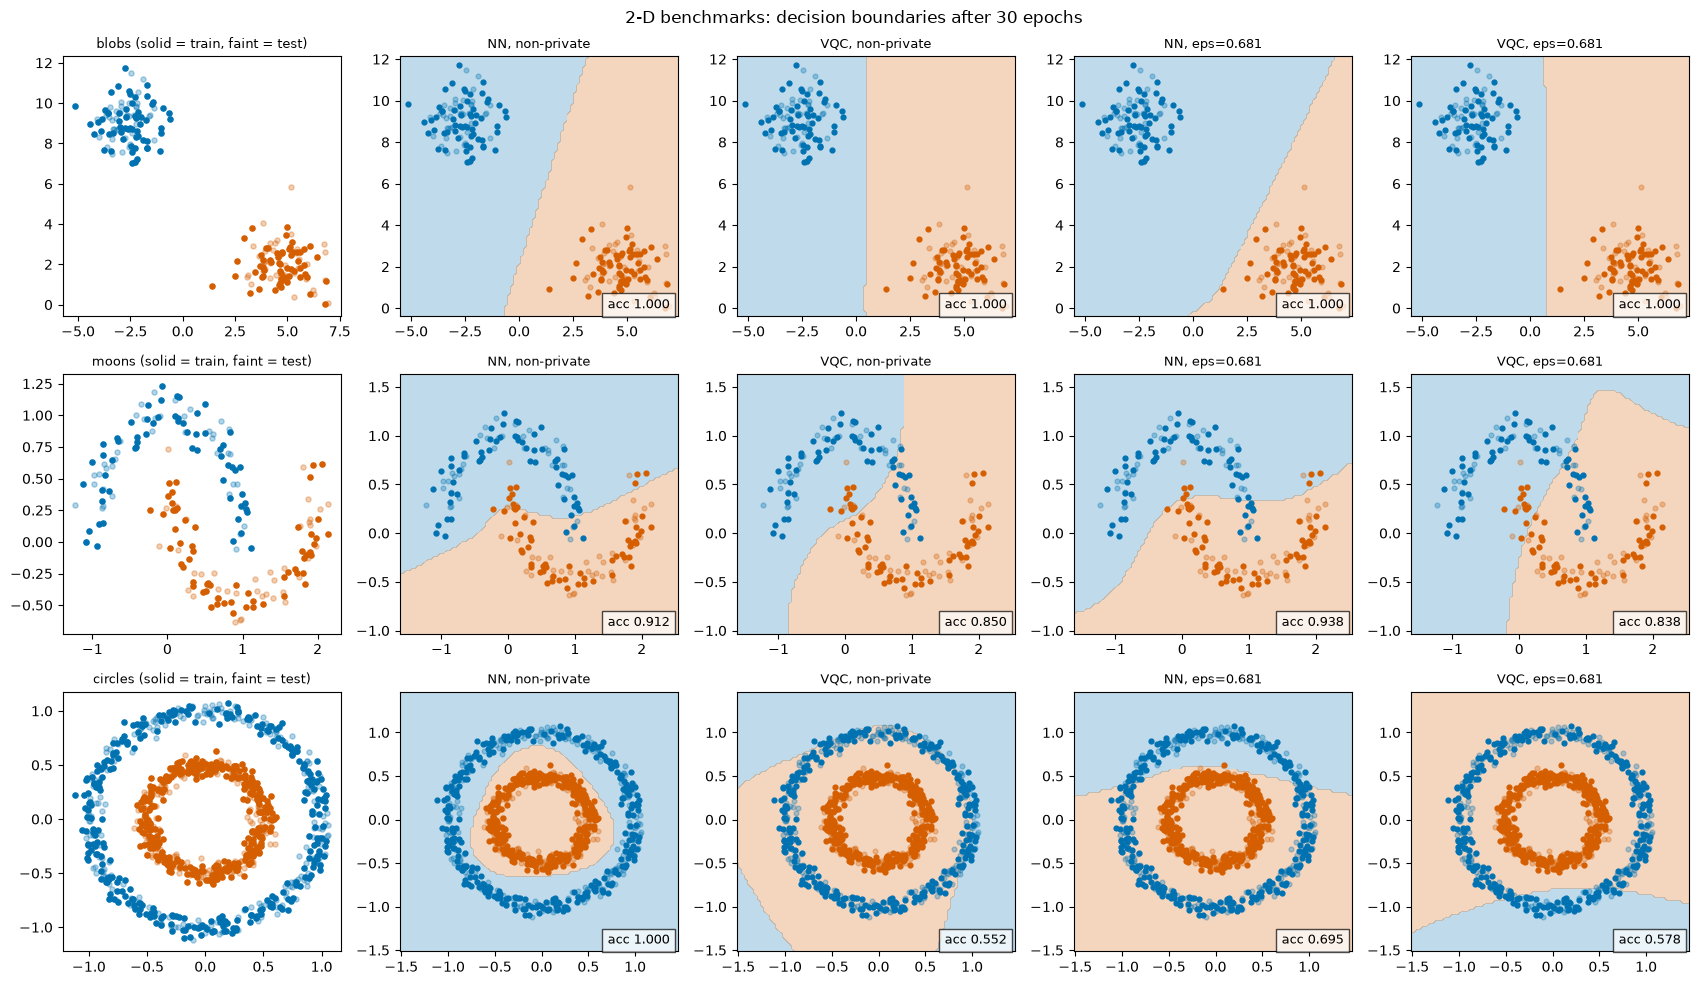

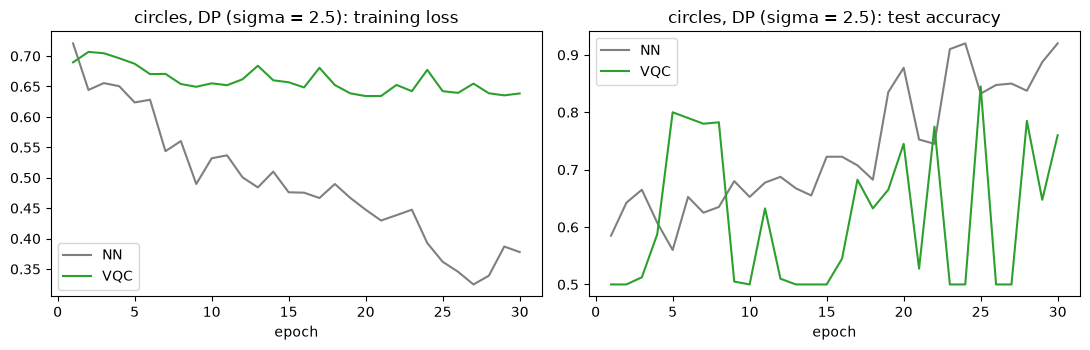

In [22]:
# Re-draw of the paper's Fig. 10: decision boundaries (seed %d) of NN and VQC without privacy and at eps = 0.681.
cols = [("NN", "nonDP"), ("VQC", "nonDP"), ("NN", "0.681"), ("VQC", "0.681")]
fig, axs = plt.subplots(3, 5, figsize=(17, 10))
for r, name in enumerate(["blobs", "moons", "circles"]):
    Xtr, Xte, ytr, yte = TASKS2D[name]; Xa = np.vstack([Xtr, Xte])
    lo, hi = Xa.min(0) - 0.4, Xa.max(0) + 0.4
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 90), np.linspace(lo[1], hi[1], 90)); grid = np.c_[gx.ravel(), gy.ravel()]
    ax = axs[r, 0]
    for d in (0, 1):
        ax.scatter(*Xtr[ytr == d].T, s=14, color=CLASS_COLORS[d]); ax.scatter(*Xte[yte == d].T, s=14, color=CLASS_COLORS[d], alpha=0.3)
    ax.set_title("%s (solid = train, faint = test)" % name, fontsize=9)
    for c, (mname, lvl) in enumerate(cols):
        ax = axs[r, c + 1]; m, th, h = keep2d[(name, lvl, mname)]
        ax.contourf(gx, gy, m.predict(th, grid).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=CLASS_COLORS, alpha=0.25)
        for d in (0, 1):
            ax.scatter(*Xtr[ytr == d].T, s=12, color=CLASS_COLORS[d]); ax.scatter(*Xte[yte == d].T, s=12, color=CLASS_COLORS[d], alpha=0.3)
        ax.text(0.97, 0.03, "acc %.3f" % h["test_acc"][-1], transform=ax.transAxes, ha="right", fontsize=9, bbox=dict(fc="white", alpha=0.7))
        ax.set_title("%s, %s" % (mname, "non-private" if lvl == "nonDP" else "eps=" + lvl), fontsize=9)
plt.suptitle("2-D benchmarks: decision boundaries after %d epochs" % EPOCHS_2D); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for mname, col in [("NN", "tab:grey"), ("VQC", "tab:green")]:
    h = keep2d[("circles", "1.628", mname)][2]
    axs[0].plot(h["epoch"], h["train_loss"], color=col, label=mname); axs[1].plot(h["test_epoch"], h["test_acc"], color=col, label=mname)
axs[0].set_title("circles, DP (sigma = 2.5): training loss"); axs[1].set_title("circles, DP (sigma = 2.5): test accuracy")
for a in axs: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 6. Experiment 2: MNIST 0 versus 1 (Table 3, Table 4, Fig. 13)

The classical net (1029 parameters) and the hybrid VQC (288 parameters, 10-qubit amplitude-encoded block 1) are trained for each noise level
of Table 3 and, as reference, without privacy. The VQC runs are the expensive part (every step simulates 32 per-sample forward and backward
passes of a 10-qubit, 80-gate circuit).

In [23]:
rows_m, keep_m = [], {}
EVAL_EPOCHS = tuple(range(5, EPOCHS + 1, 5))
t0 = time.time()

def run_mnist(mname, seed, dp, sigma, level, si):
    m = TanhNet(1024, 1) if mname == "NN" else HybridVQC("mnist")
    rng = np.random.default_rng([seed, si, 0 if mname == "NN" else 1])
    th0 = m.init(rng); t = time.time()
    th, h = train(m, th0, mn_Xtr, mn_ytr, mn_Xte, mn_yte, epochs=EPOCHS, rng=rng, dp=dp, sigma=sigma, clip=CLIP, batch=BATCH,
                  iters_per_epoch=ITERS_PER_EPOCH, lr=LR, eval_epochs=EVAL_EPOCHS if seed == SEEDS_BY_MODEL[mname][0] else ())
    rows_m.append(dict(model=mname, level=level, sigma=sigma, seed=seed, acc=h["test_acc"][-1], steps=h["steps"], secs=time.time() - t,
                       final_loss=h["train_loss"][-1]))
    if seed == SEEDS_BY_MODEL[mname][0]:
        keep_m[(mname, level)] = (m, th, h)
    return rows_m[-1]

SEEDS_BY_MODEL = {"NN": SEEDS_MNIST_NN, "VQC": SEEDS_MNIST_VQC}
for mname in ["NN", "VQC"]:                                                # non-private reference (full passes over the data)
    for seed in (SEEDS_BY_MODEL[mname] if mname == "NN" else SEEDS_BY_MODEL[mname][:1]):
        r = run_mnist(mname, seed, False, 0.0, "non-private", 99)
        print("non-private %-3s seed %d: acc %.3f  (%d steps, %.0f s)" % (mname, seed, r["acc"], r["steps"], r["secs"]))
for si in SIGMA_IDX:                                                       # one noise level per row of the paper's Table 3
    for mname in ["NN", "VQC"]:
        accs = []
        for seed in SEEDS_BY_MODEL[mname]:
            r = run_mnist(mname, seed, True, SIGMAS_MNIST[si], "dp%d" % si, si); accs.append(r["acc"])
        print("sigma %.3f (paper eps %.4f) %-3s: acc %s  [%.0f s elapsed]" % (SIGMAS_MNIST[si], PAPER_T3["eps"][si], mname,
              " ".join("%.3f" % a for a in accs), time.time() - t0))
res_m = pd.DataFrame(rows_m)
print("MNIST experiment finished in %.1f min" % ((time.time() - t0) / 60))

non-private NN  seed 42: acc 1.000  (1410 steps, 7 s)


non-private NN  seed 43: acc 0.998  (1410 steps, 5 s)


non-private NN  seed 44: acc 0.999  (1410 steps, 11 s)


non-private VQC seed 42: acc 0.994  (1410 steps, 1098 s)


sigma 1.000 (paper eps 1.7307) NN : acc 0.958 0.972 0.975  [1124 s elapsed]


...

sigma 4.083 (paper eps 0.1063) NN : acc 0.829 0.939 0.982  [4483 s elapsed]


sigma 4.083 (paper eps 0.1063) VQC: acc 0.546 0.546 0.546  [4995 s elapsed]


sigma 5.011 (paper eps 0.0715) NN : acc 0.943 0.978 0.922  [4999 s elapsed]


sigma 5.011 (paper eps 0.0715) VQC: acc 0.546 0.546 0.546  [5574 s elapsed]


MNIST experiment finished in 92.9 min


In [24]:
tab = []
for si in SIGMA_IDX:
    r = {"paper eps": round(PAPER_T3["eps"][si], 4), "sigma": round(SIGMAS_MNIST[si], 3)}
    for mname in ["NN", "VQC"]:
        a = res_m[(res_m.level == "dp%d" % si) & (res_m.model == mname)]["acc"]
        r[mname + " here"] = "%.3f +- %.3f" % (a.mean(), a.std(ddof=0)); r[mname + " paper"] = round(PAPER_T3[mname][si], 3)
    tab.append(r)
for mname in ["NN", "VQC"]:
    pass
print("Table 3 re-run: MNIST 0 vs 1, test accuracy after %d epochs (mean +- std over %d (NN) / %d (VQC) seeds; DP rows use %d iterations per epoch)"
      % (EPOCHS, len(SEEDS_MNIST_NN), len(SEEDS_MNIST_VQC), ITERS_PER_EPOCH))
print(pd.DataFrame(tab).to_string(index=False))
npd = res_m[res_m.level == "non-private"].groupby("model")["acc"].agg(["mean", "std"])
print("\nnon-private, full passes: NN %.3f +- %.3f | VQC %.3f +- %.3f" % (npd.loc["NN", "mean"], npd.loc["NN", "std"], npd.loc["VQC", "mean"], npd.loc["VQC", "std"]))
print("seconds per training run (mean): NN %.1f | VQC %.1f" % tuple(res_m.groupby("model")["secs"].mean()[["NN", "VQC"]]))

Table 3 re-run: MNIST 0 vs 1, test accuracy after 30 epochs (mean +- std over 3 (NN) / 3 (VQC) seeds; DP rows use 5 iterations per epoch)
 paper eps  sigma        NN here  NN paper       VQC here  VQC paper
    1.7307  1.000 0.968 +- 0.007     0.984 0.517 +- 0.041      0.977
    1.3448  1.125 0.968 +- 0.002     0.974 0.485 +- 0.043      0.977
    1.0747  1.256 0.966 +- 0.014     0.970 0.515 +- 0.043      0.983
    0.7325  1.513 0.976 +- 0.007     0.925 0.546 +- 0.000      0.945
    0.4059  2.006 0.944 +- 0.024     0.929 0.515 +- 0.043      0.965
    0.2600  2.503 0.944 +- 0.016     0.946 0.546 +- 0.000      0.913
    0.1823  3.058 0.973 +- 0.009     0.860 0.515 +- 0.043      0.808
    0.1360  3.537 0.907 +- 0.058     0.947 0.566 +- 0.028      0.795
    0.1063  4.083 0.917 +- 0.064     0.916 0.546 +- 0.000      0.736
    0.0715  5.011 0.948 +- 0.023     0.833 0.546 +- 0.000      0.735



non-private, full passes: NN 0.999 +- 0.001 | VQC 0.994 +- nan
seconds per training run (mean): NN 1.8 | VQC 177.8


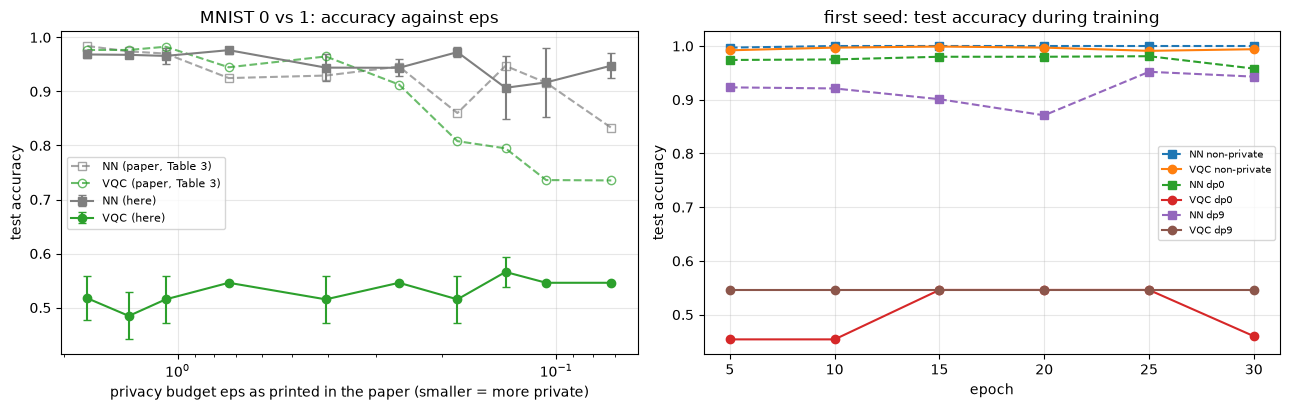

In [25]:
# Re-draw of the paper's Fig. 13 (accuracy against eps) and training curves of the first seed.
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axs[0]
for mname, col, mk in [("NN", "tab:grey", "s"), ("VQC", "tab:green", "o")]:
    xs = [PAPER_T3["eps"][si] for si in SIGMA_IDX]
    mu = [res_m[(res_m.level == "dp%d" % si) & (res_m.model == mname)]["acc"].mean() for si in SIGMA_IDX]
    sd = [res_m[(res_m.level == "dp%d" % si) & (res_m.model == mname)]["acc"].std(ddof=0) for si in SIGMA_IDX]
    ax.errorbar(xs, mu, yerr=sd, color=col, marker=mk, capsize=3, label="%s (here)" % mname)
    ax.plot(PAPER_T3["eps"], PAPER_T3[mname], color=col, ls="--", marker=mk, mfc="none", alpha=0.7, label="%s (paper, Table 3)" % mname)
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("privacy budget eps as printed in the paper (smaller = more private)"); ax.set_ylabel("test accuracy")
ax.set_title("MNIST 0 vs 1: accuracy against eps"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axs[1]
for (mname, level), (m, th, h) in keep_m.items():
    if level in ("non-private", "dp%d" % SIGMA_IDX[0], "dp%d" % SIGMA_IDX[-1]):
        ax.plot(h["test_epoch"], h["test_acc"], marker="o" if mname == "VQC" else "s", ls="-" if mname == "VQC" else "--", label="%s %s" % (mname, level))
ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy"); ax.set_title("first seed: test accuracy during training"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Why the quantum model is fragile under noise (an extension)

Two small additions that are not in the paper. First, the same training protocol with noise multipliers **below** the paper's range, to see
where the VQC stops learning. Second, a signal-to-noise comparison: the noise added to every step has norm sigma * S * sqrt(#parameters) / batch,
while the signal is the norm of the mean clipped gradient, which cannot exceed S and is tiny for a circuit that starts near the identity
(where every expectation value sits at an extremum).

In [26]:
# Extension (not in the paper): how much noise can this hybrid VQC tolerate? Same protocol, noise multipliers below the paper's range.
for k, s in enumerate(EXT_SIGMAS):
    r = run_mnist("VQC", SEEDS_MNIST_VQC[0], True, s, "ext%.2f" % s, 70 + k)
    print("VQC, sigma = %.2f (clip only if 0): test accuracy %.3f, final training loss %.3f (%.0f s)" % (s, r["acc"], r["final_loss"], r["secs"]))

VQC, sigma = 0.00 (clip only if 0): test accuracy 0.994, final training loss 0.461 (286 s)


VQC, sigma = 0.10 (clip only if 0): test accuracy 0.546, final training loss 0.469 (310 s)


VQC, sigma = 0.30 (clip only if 0): test accuracy 0.981, final training loss 0.512 (330 s)


VQC, sigma = 0.50 (clip only if 0): test accuracy 0.554, final training loss 0.563 (228 s)


VQC, sigma = 0.70 (clip only if 0): test accuracy 0.957, final training loss 0.621 (283 s)


In [27]:
# Why is the quantum model fragile under DP noise? Compare the per-step signal (norm of the mean clipped per-sample gradient) with the noise norm.
def grad_stats(model, th, X, y):
    G, _ = model.per_sample_grads(th, X, y)
    norms = np.linalg.norm(G, axis=1); clipped = G * np.minimum(1.0, CLIP / (norms + 1e-6))[:, None]
    return float(np.median(norms)), float(np.linalg.norm(clipped.mean(axis=0)))
idx = np.arange(min(256, len(mn_ytr)))
rows = []
for mname, mk in [("NN", lambda: TanhNet(1024, 1)), ("VQC", lambda: HybridVQC("mnist"))]:
    m = mk(); th_init = m.init(np.random.default_rng(SEED)); th_np = keep_m[(mname, "non-private")][1]
    for when, th in [("at initialisation", th_init), ("after non-private training", th_np)]:
        med, sig = grad_stats(m, th, mn_Xtr[idx], mn_ytr[idx])
        rows.append({"model": mname, "parameters": m.n_params, "state": when, "median per-sample |grad|": round(med, 3),
                     "|mean clipped grad| (signal)": round(sig, 3),
                     "noise norm sigma=1": round(1.0 * CLIP * np.sqrt(m.n_params) / BATCH, 3),
                     "noise norm sigma=5": round(5.0 * CLIP * np.sqrt(m.n_params) / BATCH, 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nThe noise added to every step has norm sigma * S * sqrt(#parameters) / batch; the signal cannot exceed S = %.1f (and is far below it"
      " for a circuit that starts near the identity, where <Z> sits at an extremum)." % CLIP)

model  parameters                      state  median per-sample |grad|  |mean clipped grad| (signal)  noise norm sigma=1  noise norm sigma=5
   NN        1029          at initialisation                     3.627                         0.396               1.002               5.012
   NN        1029 after non-private training                     0.000                         0.000               1.002               5.012
  VQC         288          at initialisation                     0.073                         0.031               0.530               2.652
  VQC         288 after non-private training                     0.234                         0.078               0.530               2.652

The noise added to every step has norm sigma * S * sqrt(#parameters) / batch; the signal cannot exceed S = 1.0 (and is far below it for a circuit that starts near the identity, where <Z> sits at an extremum).


## 8. Classical baselines without privacy, on the same inputs

LogisticRegression, an RBF SVC and a random forest, trained on exactly the inputs of the quantum model (raw coordinates, or the 1024 padded
pixel values / 255). They show how easy the tasks are for a standard classical method.

In [28]:
# Classical reference models without privacy, on exactly the same inputs as the quantum model (raw 2-D coordinates; the 1024 padded pixels/255).
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
rows = []
def fit_eval(name, Xtr, ytr, Xte, yte, tag):
    for mname, mk in [("LogisticRegression", lambda: LogisticRegression(max_iter=2000, random_state=SEED)),
                      ("SVC (rbf)", lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)),
                      ("RandomForest", lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1))]:
        t = time.time(); clf = mk().fit(Xtr, ytr)
        rows.append({"data": tag, "model": mname, "test accuracy": round(float((clf.predict(Xte) == yte).mean()), 3), "secs": round(time.time() - t, 1)})
for name in ["blobs", "moons", "circles"]:
    Xtr, Xte, ytr, yte = TASKS2D[name]; fit_eval(name, Xtr, ytr, Xte, yte, name)
fit_eval("mnist", mn_Xtr, mn_ytr, mn_Xte, mn_yte, "MNIST 0/1 (%d train)" % len(mn_ytr))
print(pd.DataFrame(rows).to_string(index=False))

                  data              model  test accuracy  secs
                 blobs LogisticRegression          1.000   0.6
                 blobs          SVC (rbf)          1.000   0.1
                 blobs       RandomForest          0.988   9.1
                 moons LogisticRegression          0.925   0.1
                 moons          SVC (rbf)          0.988   0.1
                 moons       RandomForest          0.975   9.1
               circles LogisticRegression          0.475   0.0
               circles          SVC (rbf)          1.000   0.1
               circles       RandomForest          0.998   9.0
MNIST 0/1 (1500 train) LogisticRegression          0.999   1.3
MNIST 0/1 (1500 train)          SVC (rbf)          1.000   4.9
MNIST 0/1 (1500 train)       RandomForest          0.999  20.6


## 9. What does the printed epsilon cover?

The accountant reproduces the paper's epsilon for **5 iterations**. The models, however, make EPOCHS x 5 noisy steps (and a full-pass epoch
would be N / 32 steps). Privacy loss accumulates with every step, so with the same noise multiplier the budget actually spent is larger.
The table composes the accountant over the iterations that were really executed in this notebook.

In [29]:
# What does the printed eps cover? The paper's eps values are reproduced by the accountant for 5 DP-SGD iterations; the model, however, is
# trained for EPOCHS x ITERS_PER_EPOCH iterations (and for a full pass over the data per epoch, far more). The same accountant, same
# sigma, same delta, composed over the iterations actually executed:
N_tr = len(mn_ytr); T_run = EPOCHS * ITERS_PER_EPOCH; T_full = EPOCHS * int(np.ceil(N_tr / BATCH))
rows = []
for si in range(10):
    s = SIGMAS_MNIST[si]
    rows.append({"paper eps": round(PAPER_T3["eps"][si], 4), "sigma": round(s, 3),
                 "eps, 5 iterations, N=1500 (as printed)": round(epsilon(1500, BATCH, s, 5, DELTA), 3),
                 "eps, this run (%d it., N=%d)" % (T_run, N_tr): round(epsilon(N_tr, BATCH, s, T_run, DELTA), 3),
                 "same, modern conversion": round(epsilon(N_tr, BATCH, s, T_run, DELTA, "modern"), 3),
                 "eps if %d full-pass epochs (%d it.)" % (EPOCHS, T_full): round(epsilon(N_tr, BATCH, s, T_full, DELTA), 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\n2-D: sigma = 2.5 / 5.0 with N = 600 (circles) and 30 epochs x 5 iterations = 150 steps:",
      [round(epsilon(600, BATCH, s, 150, DELTA), 2) for s in (2.5, 5.0)], "(paper prints 1.628 / 0.681 for all three datasets)")

 paper eps  sigma  eps, 5 iterations, N=1500 (as printed)  eps, this run (150 it., N=1500)  same, modern conversion  eps if 30 full-pass epochs (1410 it.)
    1.7307  1.000                                   1.731                            2.658                    2.179                                  6.243
    1.3448  1.125                                   1.345                            2.061                    1.662                                  5.032
    1.0747  1.256                                   1.075                            1.626                    1.291                                  4.191
    0.7325  1.513                                   0.733                            1.154                    0.904                                  3.178
    0.4059  2.006                                   0.406                            0.756                    0.591                                  2.210
    0.2600  2.503                                   0.260             


2-D: sigma = 2.5 / 5.0 with N = 600 (circles) and 30 epochs x 5 iterations = 150 steps: [1.45, 0.67] (paper prints 1.628 / 0.681 for all three datasets)


## 10. Paper versus this notebook

Every checkable claim of the paper with the notebook's value and a verdict: **reproduced** (within 0.02 accuracy, exact for counts, 0.005 for
eps), **not reached** / **exceeded** (outside the tolerance, with the gap), **cannot be checked** (not run in this mode or no data).

In [30]:
TOL = 0.02                                   # brief: "reproduced" = within 2 accuracy points
claims = []
def verdict(paper, here, tol=TOL):
    if here is None or (isinstance(here, float) and np.isnan(here)):
        return "cannot be checked", np.nan
    gap = here - paper
    return ("reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")), gap
def add(source, claim, paper, here, tol=TOL, note=""):
    v, gap = verdict(paper, here, tol)
    claims.append({"source": source, "claim": claim, "paper": paper, "here": None if here is None else round(float(here), 4),
                   "gap": None if np.isnan(gap) else round(float(gap), 4), "verdict": v, "note": note})

def mean2d(name, lvl, m):
    a = res2d[(res2d.dataset == name) & (res2d.level == lvl) & (res2d.model == m)]["acc"]; return a.mean() if len(a) else None
def meanm(level, m):
    a = res_m[(res_m.level == level) & (res_m.model == m)]["acc"]; return a.mean() if len(a) else None

for name in ["blobs", "moons", "circles"]:
    for lvl in ["nonDP", "1.628", "0.681"]:
        for k, m in enumerate(["NN", "VQC"]):
            add("Table 2", "%s %s %s accuracy" % (name, "non-private" if lvl == "nonDP" else "eps=" + lvl, m), PAPER_T2[name][lvl][k], mean2d(name, lvl, m))
for si in range(10):
    for m in ["NN", "VQC"]:
        add("Table 3", "MNIST eps=%.3f %s accuracy" % (PAPER_T3["eps"][si], m), PAPER_T3[m][si], meanm("dp%d" % si, m),
            note="" if si in SIGMA_IDX else "noise level not run in FAST_MODE")
add("Table 4", "MNIST eps=0.406 DP-NN final accuracy 0.929", 0.929, meanm("dp4", "NN")); add("Table 4", "MNIST eps=0.406 DP-VQC final accuracy 0.965", 0.965, meanm("dp4", "VQC"))
# parameter counts
for key, obj in [("VQC 2-D", HybridVQC("2d")), ("NN 2-D", TanhNet(2, 7)), ("VQC MNIST", HybridVQC("mnist")), ("NN MNIST", TanhNet(1024, 1))]:
    add("Section 'Experiments'", "number of trainable parameters, " + key, PAPER_PARAMS[key], obj.n_params, tol=0,
        note="2-7-2 net with biases has 37, the paper says 36" if key == "NN 2-D" else "")
# privacy accountant
add("Table 2", "eps for sigma=2.5 (N=120, 5 iterations)", 1.628, epsilon(120, BATCH, 2.5, 5, DELTA), tol=0.005)
add("Table 2", "eps for sigma=5.0 (N=120, 5 iterations)", 0.681, epsilon(120, BATCH, 5.0, 5, DELTA), tol=0.005)
add("Table 3", "eps for sigma=1.0 (N=1500, 5 iterations)", PAPER_T3["eps"][0], epsilon(1500, BATCH, 1.0, 5, DELTA), tol=0.01)
# qualitative statements (checked on this notebook's means)
def have(idx_list, level="dp"):
    return all(("dp%d" % i) in set(res_m.level) for i in idx_list)
def qual(source, text, idx_list, test):
    if not have(idx_list):
        claims.append({"source": source, "claim": text, "paper": "true", "here": None, "gap": None, "verdict": "cannot be checked", "note": "rows not run in FAST_MODE"}); return
    ok = all(test(i) for i in idx_list)
    claims.append({"source": source, "claim": text, "paper": "true", "here": str(ok), "gap": None, "verdict": "reproduced" if ok else "not reached",
                   "note": "; ".join("eps %.3f: VQC %.3f, NN %.3f" % (PAPER_T3["eps"][i], meanm("dp%d" % i, "VQC"), meanm("dp%d" % i, "NN")) for i in idx_list)})
qual("Abstract/Discussion", "DP-VQC exceeds 90% accuracy for eps between 0.5 and 1.0 (Table 3 row eps=0.73)", [3], lambda i: meanm("dp%d" % i, "VQC") > 0.90)
qual("Table 3 caption", "DP-VQC is at least as accurate as the DP-NN for eps between 0.41 and 1.34", [1, 2, 3, 4], lambda i: meanm("dp%d" % i, "VQC") >= meanm("dp%d" % i, "NN"))
qual("Discussion", "for eps below 0.25 the classical net is more accurate than the VQC", [6, 7, 8, 9], lambda i: meanm("dp%d" % i, "NN") > meanm("dp%d" % i, "VQC"))
ok = all(mean2d("circles", l, "VQC") - mean2d("circles", l, "NN") >= 0.10 for l in ["1.628", "0.681"])
claims.append({"source": "Fig. 8 / Table 2", "claim": "under DP the VQC beats the NN on 'circles' by about 14 points (>= 10 here)", "paper": "true", "here": str(ok),
               "gap": None, "verdict": "reproduced" if ok else "not reached",
               "note": "; ".join("eps=%s: VQC %.3f vs NN %.3f" % (l, mean2d("circles", l, "VQC"), mean2d("circles", l, "NN")) for l in ["1.628", "0.681"])})
add("Abstract", "VQC uses 28% of the NN's parameters on MNIST (288/1029 = 0.2799)", 0.2799, HybridVQC("mnist").n_params / TanhNet(1024, 1).n_params, tol=0.001)

verd = pd.DataFrame(claims)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_rows", 200)
print(verd[["source", "claim", "paper", "here", "gap", "verdict"]].to_string(index=False))
print("\nVERDICT COUNTS:", verd["verdict"].value_counts().to_dict(), "of", len(verd), "claims")
print(verd.groupby("source")["verdict"].value_counts().unstack(fill_value=0).to_string())

               source                                                                          claim     paper    here     gap     verdict
              Table 2                                                  blobs non-private NN accuracy       1.0     1.0  0.0000  reproduced
              Table 2                                                 blobs non-private VQC accuracy      0.96     1.0  0.0400    exceeded
              Table 2                                                    blobs eps=1.628 NN accuracy      0.98   0.995  0.0150  reproduced
              Table 2                                                   blobs eps=1.628 VQC accuracy      0.92     1.0  0.0800    exceeded
              Table 2                                                    blobs eps=0.681 NN accuracy      0.98    0.99  0.0100  reproduced
              Table 2                                                   blobs eps=0.681 VQC accuracy      0.92     1.0  0.0800    exceeded
              Table 2      


VERDICT COUNTS: {'not reached': 23, 'reproduced': 20, 'exceeded': 9} of 52 claims


verdict                exceeded  not reached  reproduced
source                                                  
Abstract                      0            0           1
Abstract/Discussion           0            1           0
Discussion                    0            0           1
Fig. 8 / Table 2              0            1           0
Section 'Experiments'         1            0           3
Table 2                       5            8           7
Table 3                       3           11           7
Table 3 caption               0            1           0
Table 4                       0            1           1


## Reading the paper critically

﻿**What was reproduced.** The privacy accountant (epsilon = 1.628 and 0.681 for the 2-D noise levels, 1.7321 against 1.7307 for MNIST at sigma = 1, and 3.01 on the
published TF-Privacy example), the parameter counts (288 and 1029; 24 for the 2-D VQC, while a 2-7-2 net with biases has 37 rather than 36),
the classical network under DP-SGD (within 2 accuracy points of the paper in 6 of the 10 rows of Table 3, above it in 3 and below it in 1; blobs and moons broadly agree) and the non-private VQC on MNIST (0.994) and on the easy 2-D sets.

**What was not.** (1) The central claim, that the **hybrid VQC keeps 0.74 to 0.98 accuracy on MNIST at every noise level of Table 3**, is not reproduced:
for all ten noise multipliers (1.0 to 5.0) the DP-VQC stays at chance level (it predicts one class, accuracy 0.546 or 0.454; mean over three seeds about 0.52), although the
same code reaches 0.994 without privacy and with clipping only (sigma = 0), and gets 0.98 (sigma = 0.3) and 0.96 (sigma = 0.7) in single runs of the extension, but
0.55 at sigma = 0.1 and 0.5. The signal-to-noise table in Section 7 gives the reason within this implementation: a circuit that starts at the identity has per-sample
gradients of norm about 0.07, so the mean clipped gradient (norm 0.03) is buried under noise of norm 0.53 sigma, while the classical net starts with gradients of norm 3.6 that clip to 1.
Which unreported detail makes the paper's circuit train under noise (the CNOT pattern, the read-out qubits, the initial angles, the loss scaling, the optimiser variant or the number of iterations)
cannot be told from the text; an exploratory run outside this notebook with full-pass epochs (1410 noisy steps) was also at or near chance for sigma = 1 and 5.
(2) On the 2-D sets the VQC reaches the paper's values for moons (within 0.03 to 0.04) and exceeds them for blobs (1.00 against 0.92 to 0.96), but **not for circles**: 0.79 +- 0.17 without privacy
(some seeds converge to 0.99, others stay near 0.5, because the near-identity start sits on a saddle) and 0.73 / 0.53 under privacy, against 0.998 / 1.00 in the paper. The claim that the DP-VQC beats the DP-NN by 14 points on "circles" is therefore not reproduced here.

**The printed epsilon covers 5 iterations.** The accountant reproduces the paper's epsilon exactly only for N = 120 (2-D) or N = 1500 (MNIST) and **5** DP-SGD iterations, the "# of Iter." of Table 1.
A 30-epoch run of 5 iterations per epoch performs 150 noisy steps; composing the same accountant over them gives epsilon = 2.66 instead of 1.73 at sigma = 1 and 0.27 instead of 0.07 at sigma = 5; if each epoch is a full pass over the data it is 6.2 and 0.80 (Section 9).
This is an inference from the numbers, not a statement of the paper, but if it is right the headline "eps between 0.5 and 1.0" is an under-estimate of the privacy loss of the trained model by a factor of about 1.5 to 4.

**The comparison with the classical model.** The "quantum advantage" is measured against a 1024-1-2 network with a single hidden unit. Standard classical models trained on the same inputs reach 0.999 to 1.000 on MNIST 0 vs 1 (Section 8)
and a tiny network keeps 0.91 to 0.98 under DP-SGD in this notebook at every noise level, so the task is far too easy to separate models, and the fewer-parameters argument (288 against 1029) compares unlike things.
The accuracy-against-epsilon curve of Table 3 is not monotone (for example the NN scores 0.947 at epsilon 0.136 and 0.929 at 0.406), which fits single runs; in this notebook the standard deviation over three seeds is up to 0.06 for the NN and a failing VQC flips between 0.454 and 0.546.

**What is never tested.** The paper motivates DP by membership inference and data extraction but never runs an attack, so only the theoretical (epsilon, delta) is reported (exercise 1). Hyper-parameters are said to be "tuned using preliminary experiments" on unspecified data.
The NISQ claim is not examined either: with the parameter-shift rule one DP-SGD step of the MNIST model needs 32 samples x 288 parameters x 2 shifts = 18,432 circuit executions (times the shots) and every circuit starts with a 1024-amplitude state preparation, whose gate cost the paper does not count. Everything was simulated without noise.

## Exercises

1. **Membership inference.** Train the classical net on the MNIST task without DP and with sigma = 1, then attack both with a loss-threshold
   membership-inference test (members: training images, non-members: test images; report the attack AUC). The paper motivates DP with such attacks
   but never measures one. How much does DP reduce the AUC?
2. **Honest budget.** Change `ITERS_PER_EPOCH` to a full pass (`int(np.ceil(N/32))`) for the classical net and re-compute epsilon with the accountant.
   Which sigma gives epsilon = 1 for the whole run, and what accuracy does the net keep?
3. **Initialisation.** The VQC starts almost at the identity, where the gradient is nearly zero. Re-train with `HybridVQC.init` returning
   N(0, 0.5^2) angles and compare the per-sample gradient norms (Section 7) and the accuracy at sigma = 1.
4. **Entanglers.** Replace the CNOT ring by a chain without the closing gate, or by CZ gates (change `cnot_ring_perm` and `make_qnode` together; the
   equivalence assertion will tell you whether they still agree). Does the accuracy under noise change?
5. **A fairer classical control.** The paper's classical net has one hidden unit. Give it 8 hidden units (`TanhNet(1024, 8)`), keep DP-SGD, and
   repeat the comparison of Table 3. Does the "quantum advantage" survive?